In [1]:
"""
2D Heisenberg anisótropo XYZ - TENSOR CONTRACTION
==================================================
Sistema: 2D grid L×L sin condiciones de frontera periódicas

H = Σᵢ Zᵢ  +  Σ_{<i,j>} (Jx·XᵢXⱼ + Jy·YᵢYⱼ + Jz·ZᵢZⱼ)

Partición:
  H₀ = Σᵢ Zᵢ                                          (campo — gates 1 qubit)
  Hₖ = Jx·XᵢXⱼ + Jy·YᵢYⱼ + Jz·ZᵢZⱼ  por enlace       (interacción — gates 4×4)

Métodos de 1° orden:
  1. LTS:  e^{-iH₀δt} · ∏ₖ e^{-iHₖδt}
  2. PS:   e^{-iH₀δt/2} · ∏ₖ e^{-iHₖδt} · e^{-iH₀δt/2}
  3. THRIFT:   ∏ₖ [e^{+i(Zᵢ+Zⱼ)δt} · e^{-i(Zᵢ+Zⱼ+Hₖ)δt}] · e^{-iH₀δt}
  4. λ-method: e^{-iH₀λδt} · ∏ₖ e^{-iHₖδt/2} · e^{-iH₀(1-2λ)δt}
               · ∏ₖ e^{-iHₖδt/2} · e^{-iH₀λδt}

Métodos de 2° orden (palindrómicos U(dt/2)·U†(dt/2)):
  5. LTS2: U_LTS(dt/2) · U†_trotter(dt/2)
  6. PS2:  U_PS(dt/2)  · U†_strang(dt/2)
  7. THRIFT2:  U_thrift(dt/2)  · U†_thrift(dt/2)
  8. ULam2:      Proposición — λ̃·H₀, ∏↑∏↓(dt/4), (1-2λ̃)·H₀, ∏↑∏↓(dt/4), λ̃·H₀
  9. OG:  Generalización de OG et al. con λ̃

Persistencia de resultados:
  - save_results()  : guarda errors, nsteps, dt y params en results/<run>/
  - load_results()  : reconstruye todo para re-graficar sin recalcular
  - plot_results()  : función de plot independiente, reutilizable
  - compare_runs()  : superpone curvas de distintos experimentos
"""

import os
import json
import time
import numpy as np
from scipy.linalg import expm
import matplotlib.pyplot as plt
from concurrent.futures import ProcessPoolExecutor
from multiprocessing import cpu_count

# -----------------------------------------------------------------------
# CONSTANTE λ̃
# -----------------------------------------------------------------------
LAM = 0.5 - np.sqrt(3) / 6   # λ̃ ≈ 0.211325

# -----------------------------------------------------------------------
# PAULI MATRICES
# -----------------------------------------------------------------------
I2 = np.eye(2, dtype=complex)
X2 = np.array([[0, 1],   [1,  0]], dtype=complex)
Y2 = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z2 = np.array([[1, 0],   [0, -1]], dtype=complex)

XX4 = np.kron(X2, X2)
YY4 = np.kron(Y2, Y2)
ZZ4 = np.kron(Z2, Z2)


# -----------------------------------------------------------------------
# GATE APPLICATION VIA TENSOR CONTRACTION
# -----------------------------------------------------------------------

def apply_1q_gate(state, gate, qubit, N):
    result = np.tensordot(gate, state, axes=([1], [qubit]))
    return np.moveaxis(result, 0, qubit)


def apply_2q_gate(state, gate, qubit1, qubit2, N):
    if gate.shape == (4, 4):
        gate = gate.reshape(2, 2, 2, 2)
    result = np.tensordot(gate, state, axes=([2, 3], [qubit1, qubit2]))
    remaining = [i for i in range(N) if i != qubit1 and i != qubit2]
    axes = [None] * N
    axes[qubit1] = 0
    axes[qubit2] = 1
    for k, orig in enumerate(remaining):
        axes[orig] = 2 + k
    return np.transpose(result, axes)


# -----------------------------------------------------------------------
# GATE CACHE
# -----------------------------------------------------------------------

class GateCache:
    def __init__(self):
        self._cache = {}

    def get_1q(self, label, coeff):
        key = (label, coeff)
        if key not in self._cache:
            if label == 'Z':
                self._cache[key] = expm(coeff * Z2)
        return self._cache[key]

    def get_int(self, Jx, Jy, Jz, dt):
        """e^{-i·dt·(Jx·XX + Jy·YY + Jz·ZZ)} — gate de interacción por enlace."""
        key = ('int', Jx, Jy, Jz, dt)
        if key not in self._cache:
            H_int = Jx * XX4 + Jy * YY4 + Jz * ZZ4
            self._cache[key] = expm(-1j * dt * H_int)
        return self._cache[key]

    def get_thrift_pair(self, dt, Jx, Jy, Jz):
        """
        Gate 4×4 para THRIFT por enlace:
          e^{+i(Zᵢ+Zⱼ)δt} · e^{-i(Zᵢ+Zⱼ + Jx·XX + Jy·YY + Jz·ZZ)δt}
        """
        key = ('thrift', dt, Jx, Jy, Jz)
        if key not in self._cache:
            ZZ2   = np.kron(Z2, I2) + np.kron(I2, Z2)
            H_int = Jx * XX4 + Jy * YY4 + Jz * ZZ4
            self._cache[key] = expm(+1j * dt * ZZ2) @ expm(-1j * dt * (ZZ2 + H_int))
        return self._cache[key]

    def get_thrift_pair_dag(self, dt, Jx, Jy, Jz):
        """
        Gate 4×4 adjunto de THRIFT por enlace — orden invertido de los dos factores:
          e^{+i(Zᵢ+Zⱼ + Jx·XX + Jy·YY + Jz·ZZ)δt} · e^{-i(Zᵢ+Zⱼ)δt}
        """
        key = ('thrift_dag', dt, Jx, Jy, Jz)
        if key not in self._cache:
            ZZ2   = np.kron(Z2, I2) + np.kron(I2, Z2)
            H_int = Jx * XX4 + Jy * YY4 + Jz * ZZ4
            self._cache[key] = expm(+1j * dt * (ZZ2 + H_int)) @ expm(-1j * dt * ZZ2)
        return self._cache[key]

    def clear(self):
        self._cache.clear()


# -----------------------------------------------------------------------
# MODELO
# -----------------------------------------------------------------------

class HeisenbergAniso2D:
    """
    H = Σᵢ Zᵢ  +  Σ_{<i,j>} (Jx·XᵢXⱼ + Jy·YᵢYⱼ + Jz·ZᵢZⱼ)
    sin condiciones de frontera periódicas.
    """
    def __init__(self, L, Jx=0.1, Jy=0.15, Jz=0.05):
        self.L   = L
        self.N   = L * L
        self.Jx  = Jx
        self.Jy  = Jy
        self.Jz  = Jz
        self.dim = 2 ** self.N
        self.pairs = self._build_pairs()
        self.m   = len(self.pairs)

    def _build_pairs(self):
        L = self.L
        pairs = []
        for row in range(L):
            for col in range(L - 1):
                pairs.append((row * L + col, row * L + col + 1, 'H'))
        for row in range(L - 1):
            for col in range(L):
                pairs.append((row * L + col, (row + 1) * L + col, 'V'))
        return pairs

    def build_hamiltonian(self):
        """Construye H completo como matriz densa vía sparse."""
        from scipy.sparse import csr_matrix, kron as skron
        I_s = csr_matrix(I2)
        X_s = csr_matrix(X2)
        Y_s = csr_matrix(Y2)
        Z_s = csr_matrix(Z2)
        H = csr_matrix((self.dim, self.dim), dtype=complex)

        for k in range(self.N):
            op = csr_matrix([[1.0 + 0j]])
            for q in range(self.N):
                op = skron(op, Z_s if q == k else I_s, format='csr')
            H = H + op

        for (i, j, _) in self.pairs:
            for J_val, P_s in [(self.Jx, X_s), (self.Jy, Y_s), (self.Jz, Z_s)]:
                op = csr_matrix([[1.0 + 0j]])
                for q in range(self.N):
                    if   q == i: op = skron(op, P_s, format='csr')
                    elif q == j: op = skron(op, P_s, format='csr')
                    else:        op = skron(op, I_s, format='csr')
                H = H + J_val * op

        return H.toarray()


# -----------------------------------------------------------------------
# EVOLVER
# -----------------------------------------------------------------------

class Evolver:

    def __init__(self, system: HeisenbergAniso2D, t: float, cache: GateCache):
        self.sys   = system
        self.t     = t
        self.cache = cache
        self.N     = system.N
        self.dim   = system.dim

    def _apply_Z_all(self, state, coeff):
        g = self.cache.get_1q('Z', coeff)
        for k in range(self.N):
            state = apply_1q_gate(state, g, k, self.N)
        return state

    # ── Batch helpers ────────────────────────────────────────────────

    def _batch_apply_1q(self, states, gate, qubit):
        result = np.tensordot(gate, states, axes=([1], [qubit + 1]))
        return np.moveaxis(result, 0, qubit + 1)

    def _batch_apply_2q(self, states, gate, q1, q2):
        if gate.shape == (4, 4):
            gate = gate.reshape(2, 2, 2, 2)
        result = np.tensordot(gate, states, axes=([2, 3], [q1 + 1, q2 + 1]))
        remaining = [0] + [i + 1 for i in range(self.N) if i != q1 and i != q2]
        axes    = [None] * (self.N + 1)
        axes[0]      = 2
        axes[q1 + 1] = 0
        axes[q2 + 1] = 1
        ri = 3
        for orig in remaining[1:]:
            axes[orig] = ri
            ri += 1
        return np.transpose(result, axes)

    def _batch_Z_all(self, states, gate_Z):
        for q in range(self.N):
            states = self._batch_apply_1q(states, gate_Z, q)
        return states

    def _batch_int_all(self, states, gate_int):
        for (i, j, _) in self.sys.pairs:
            states = self._batch_apply_2q(states, gate_int, i, j)
        return states

    def _batch_int_all_reverse(self, states, gate_int):
        """Aplica gates de interacción en orden INVERSO de self.sys.pairs."""
        for (i, j, _) in reversed(self.sys.pairs):
            states = self._batch_apply_2q(states, gate_int, i, j)
        return states

    def compute_unitary(self, nsteps, method, lam=None):
        dt     = self.t / nsteps
        states = np.eye(self.dim, dtype=complex).reshape([self.dim] + [2] * self.N)
        self.cache.clear()

        Jx, Jy, Jz = self.sys.Jx, self.sys.Jy, self.sys.Jz

        # pre-cache para métodos clásicos (dt fijo todo el run)
        if method == 'lts':
            gZ   = self.cache.get_1q('Z', -1j * dt)
            gInt = self.cache.get_int(Jx, Jy, Jz, dt)
        elif method == 'ps':
            gZh  = self.cache.get_1q('Z', -1j * dt / 2)
            gInt = self.cache.get_int(Jx, Jy, Jz, dt)
        elif method == 'thrift':
            gZ   = self.cache.get_1q('Z', -1j * dt)
            gTH  = self.cache.get_thrift_pair(dt, Jx, Jy, Jz)
        elif method == 'u_lambda':
            gZl  = self.cache.get_1q('Z', -1j * lam * dt)
            gZm  = self.cache.get_1q('Z', -1j * (1 - 2 * lam) * dt)
            gInt = self.cache.get_int(Jx, Jy, Jz, dt / 2)
        # métodos 2° orden: pre-cachean con dt/2, GateCache evita recomputos entre pasos
        elif method == 'lts2':
            h     = dt / 2
            gZh   = self.cache.get_1q('Z', -1j * h)
            gInth = self.cache.get_int(Jx, Jy, Jz, h)
        elif method == 'ps2':
            h     = dt / 2
            gZq   = self.cache.get_1q('Z', -1j * h / 2)    # dt/4
            gZfus = self.cache.get_1q('Z', -1j * h)         # dt/2 (H₀ fusionado del medio)
            gInth = self.cache.get_int(Jx, Jy, Jz, h)
        elif method == 'thrift2':
            h      = dt / 2
            gZh    = self.cache.get_1q('Z', -1j * h)
            gTHh   = self.cache.get_thrift_pair(h, Jx, Jy, Jz)
            gTHhd  = self.cache.get_thrift_pair_dag(-h, Jx, Jy, Jz)
        elif method == 'u_lambda2':
            _lam  = lam if lam is not None else LAM
            gZl   = self.cache.get_1q('Z', -1j * _lam * dt)
            gZm   = self.cache.get_1q('Z', -1j * (1 - 2 * _lam) * dt)
            gInt4 = self.cache.get_int(Jx, Jy, Jz, dt / 4)
        elif method == 'og':
            _lam  = lam if lam is not None else LAM
            gZl   = self.cache.get_1q('Z', -1j * _lam * dt)
            gZm   = self.cache.get_1q('Z', -1j * (1 - 2 * _lam) * dt)
            gIntL = self.cache.get_int(Jx, Jy, Jz, _lam * dt)
            gIntM = self.cache.get_int(Jx, Jy, Jz, (1 - 2 * _lam) * dt / 2)

        for _ in range(nsteps):

            # ── métodos 1° orden ─────────────────────────────────────

            if method == 'lts':
                states = self._batch_int_all(states, gInt)
                states = self._batch_Z_all(states, gZ)
                
            elif method == 'ps':
                states = self._batch_Z_all(states, gZh)
                states = self._batch_int_all(states, gInt)
                states = self._batch_Z_all(states, gZh)

            elif method == 'thrift':
                states = self._batch_int_all(states, gTH)
                states = self._batch_Z_all(states, gZ)

            elif method == 'u_lambda':
                states = self._batch_Z_all(states, gZl)
                states = self._batch_int_all(states, gInt)
                states = self._batch_Z_all(states, gZm)
                states = self._batch_int_all(states, gInt)
                states = self._batch_Z_all(states, gZl)

            # ── métodos 2° orden ─────────────────────────────────────

            elif method == 'lts2':
                # U_LTS(dt/2):   H₀ → ∏↑ Hₖ
                # U†_trotter(dt/2):  ∏↓ Hₖ → H₀
                states = self._batch_Z_all(states, gZh)
                states = self._batch_int_all_reverse(states, gInth)
                states = self._batch_int_all(states, gInth)
                states = self._batch_Z_all(states, gZh)

            elif method == 'ps2':
                # U_PS(dt/2):  H₀/2 → ∏↑ Hₖ → H₀/2
                # U†_strang(dt/2): H₀/2 → ∏↓ Hₖ → H₀/2
                # los dos H₀/2 del medio se fusionan en H₀
                states = self._batch_Z_all(states, gZq)
                states = self._batch_int_all_reverse(states, gInth)
                states = self._batch_Z_all(states, gZfus)       # fusionado
                states = self._batch_int_all(states, gInth)
                states = self._batch_Z_all(states, gZq)

            elif method == 'thrift2':
                # e^{-iH₀·dt/2} · ∏↑ gTH(dt/2) · ∏↓ gTH†(-dt/2) · e^{-iH₀·dt/2}
                states = self._batch_Z_all(states, gZh)
                states = self._batch_int_all_reverse(states, gTHhd)
                states = self._batch_int_all(states, gTHh)
                states = self._batch_Z_all(states, gZh)

            elif method == 'u_lambda2':
                # e^{-iλ̃H₀dt} · [∏↑∏↓ e^{-iHₖdt/4}]
                # · e^{-i(1-2λ̃)H₀dt} · [∏↑∏↓ e^{-iHₖdt/4}] · e^{-iλ̃H₀dt}
                states = self._batch_Z_all(states, gZl)
                states = self._batch_int_all(states, gInt4)              # ∏↑
                states = self._batch_int_all_reverse(states, gInt4)      # ∏↓
                states = self._batch_Z_all(states, gZm)
                states = self._batch_int_all(states, gInt4)              # ∏↑
                states = self._batch_int_all_reverse(states, gInt4)      # ∏↓
                states = self._batch_Z_all(states, gZl)

            elif method == 'og':
                # e^{-iλ̃H₀} · [∏↑ e^{-iλ̃Hₖ} · ∏↓ e^{-i(1-2λ̃)Hₖ/2}]
                # · e^{-i(1-2λ̃)H₀} · [∏↑ e^{-i(1-2λ̃)Hₖ/2} · ∏↓ e^{-iλ̃Hₖ}]
                # · e^{-iλ̃H₀}
                states = self._batch_Z_all(states, gZl)
                states = self._batch_int_all(states, gIntL)              # ∏↑ λ̃
                states = self._batch_int_all_reverse(states, gIntM)      # ∏↓ (1-2λ̃)/2
                states = self._batch_Z_all(states, gZm)
                states = self._batch_int_all(states, gIntM)              # ∏↑ (1-2λ̃)/2
                states = self._batch_int_all_reverse(states, gIntL)      # ∏↓ λ̃
                states = self._batch_Z_all(states, gZl)

        return states.reshape(self.dim, self.dim).T


# -----------------------------------------------------------------------
# WORKER (nivel de módulo para pickle)
# -----------------------------------------------------------------------

def _worker(task):
    n, method, lam, L, Jx, Jy, Jz, t_val, U_exact_flat, dim = task
    system  = HeisenbergAniso2D(L, Jx, Jy, Jz)
    cache   = GateCache()
    evolver = Evolver(system, t_val, cache)
    U       = evolver.compute_unitary(n, method, lam=lam)
    U_exact = U_exact_flat.reshape(dim, dim)
    return np.linalg.norm(U - U_exact, 'fro')


# -----------------------------------------------------------------------
# SAVE / LOAD RESULTADOS
# -----------------------------------------------------------------------

def save_results(errors, nsteps_list, dt_list, params, base_dir='results'):
    L  = params['L']
    Jx = params['Jx']
    Jy = params['Jy']
    Jz = params['Jz']
    t  = params['t']

    run_dir = os.path.join(
        base_dir,
        f"XYZ2D_L{L}_Jx{Jx}_Jy{Jy}_Jz{Jz}_t{t}"
    )
    os.makedirs(run_dir, exist_ok=True)

    with open(os.path.join(run_dir, 'params.json'), 'w') as f:
        json.dump(params, f, indent=2)

    method_names = list(errors.keys())
    with open(os.path.join(run_dir, 'method_names.json'), 'w') as f:
        json.dump(method_names, f, indent=2)

    np.save(os.path.join(run_dir, 'nsteps.npy'), nsteps_list)
    np.save(os.path.join(run_dir, 'dt.npy'),     dt_list)

    for idx, (name, err_list) in enumerate(errors.items()):
        np.save(
            os.path.join(run_dir, f'errors_{idx:02d}.npy'),
            np.array(err_list, dtype=float)
        )

    print(f"[save] Resultados guardados en: {run_dir}/")
    print(f"       Métodos: {method_names}")
    return run_dir


def load_results(run_dir):
    with open(os.path.join(run_dir, 'params.json')) as f:
        params = json.load(f)

    with open(os.path.join(run_dir, 'method_names.json')) as f:
        method_names = json.load(f)

    nsteps_list = np.load(os.path.join(run_dir, 'nsteps.npy'))
    dt_list     = np.load(os.path.join(run_dir, 'dt.npy'))

    errors = {}
    for idx, name in enumerate(method_names):
        fpath = os.path.join(run_dir, f'errors_{idx:02d}.npy')
        errors[name] = np.load(fpath).tolist()

    print(f"[load] Cargado: {run_dir}")
    print(f"       L={params['L']}  Jx={params['Jx']}  Jy={params['Jy']}  "
          f"Jz={params['Jz']}  t={params['t']}")
    print(f"       Métodos: {method_names}")
    print(f"       Puntos por método: {len(nsteps_list)}")
    return errors, nsteps_list, dt_list, params


# -----------------------------------------------------------------------
# PLOT
# -----------------------------------------------------------------------

def plot_results(errors, nsteps_list, dt_list, params,
                 save_fig=True, show=True, out_dir='figures'):
    L  = params['L']
    Jx = params['Jx']
    Jy = params['Jy']
    Jz = params['Jz']
    t  = params['t']

    base_methods   = ['LTS', 'PS', 'THRIFT',
                      'LTS2', 'PS2', 'THRIFT2', 'ULam2', 'OG']
    other_methods  = [k for k in errors if k not in base_methods]

    cmap       = plt.cm.plasma
    lam_colors = [cmap(v) for v in np.linspace(0.15, 0.80, max(len(other_methods), 1))]

    log_dt  = np.log(np.array(dt_list, dtype=float))
    slopes  = {}
    idx_fit = slice(-8, None)
    for name, err_list in errors.items():
        log_e = np.log(np.array(err_list, dtype=float))
        valid = np.isfinite(log_e[idx_fit]) & np.isfinite(log_dt[idx_fit])
        if valid.sum() > 2:
            slopes[name] = np.polyfit(log_dt[idx_fit][valid],
                                      log_e[idx_fit][valid], 1)[0]
        else:
            slopes[name] = float('nan')

    system_tmp = HeisenbergAniso2D(L, Jx, Jy, Jz)

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    fig.suptitle(
        f'2D XYZ  {L}×{L}  (Jx={Jx}, Jy={Jy}, Jz={Jz}, t={t},  '
        f'{system_tmp.m} enlaces)\n'
        f'H = ΣZᵢ + Jx·ΣXᵢXⱼ + Jy·ΣYᵢYⱼ + Jz·ΣZᵢZⱼ',
        fontsize=12, fontweight='bold', y=1.01
    )

    styles = {
        'LTS':  dict(marker='o', color='black',       lw=2.0, ms=6, ls='-'),
        'PS':   dict(marker='D', color='royalblue',   lw=2.0, ms=6, ls='-'),
        'THRIFT':   dict(marker='s', color='crimson',     lw=2.0, ms=6, ls='-'),
        'LTS2': dict(marker='o', color='black',       lw=2.0, ms=6, ls='--'),
        'PS2':  dict(marker='D', color='royalblue',   lw=2.0, ms=6, ls='--'),
        'THRIFT2':  dict(marker='s', color='crimson',     lw=2.0, ms=6, ls='--'),
        'ULam2':      dict(marker='^', color='darkorange',  lw=2.0, ms=6, ls='--'),
        'OG':  dict(marker='v', color='darkgreen',   lw=2.0, ms=6, ls='--'),
    }

    for ax, xdata, xlabel in zip(
        axes,
        [nsteps_list, dt_list],
        ['Número de pasos n', 'Paso de tiempo δt = t/n']
    ):
        for name in base_methods:
            if name in errors:
                sl  = slopes.get(name, float('nan'))
                kw  = styles[name]
                lbl = f"{name}  (p={sl:.2f})"
                ax.loglog(xdata, errors[name], label=lbl,
                          marker=kw['marker'], color=kw['color'],
                          lw=kw['lw'], ms=kw['ms'], linestyle=kw['ls'])

        for idx, name in enumerate(other_methods):
            sl  = slopes.get(name, float('nan'))
            ax.loglog(xdata, errors[name],
                      marker='^', linestyle='-',
                      color=lam_colors[idx], lw=1.8, ms=5,
                      label=f"{name}  (p={sl:.2f})", alpha=0.85)

        if 'δt' in xlabel:
            dt_arr = np.array(dt_list, dtype=float)
            ax.loglog(dt_arr, 0.5  * dt_arr,    'k--', alpha=0.3, lw=1.2, label='O(δt)')
            ax.loglog(dt_arr, 0.05 * dt_arr**2, 'k:',  alpha=0.3, lw=1.2, label='O(δt²)')

        ax.set_xlabel(xlabel, fontsize=12)
        ax.set_ylabel('Error  ||U_aprox − U_exact||_F', fontsize=12)
        ax.grid(True, which='both', alpha=0.25)
        ax.legend(fontsize=8, ncol=2, framealpha=0.9)

    plt.tight_layout()

    if save_fig:
        os.makedirs(out_dir, exist_ok=True)
        fname = os.path.join(out_dir, f'XYZ2D_L{L}_Jx{Jx}_Jy{Jy}_Jz{Jz}.png')
        plt.savefig(fname, dpi=150, bbox_inches='tight')
        print(f"[plot] Guardado: {fname}")

    if show:
        plt.show()

    return fig


# -----------------------------------------------------------------------
# UTILIDAD: comparar varios runs
# -----------------------------------------------------------------------

def compare_runs(run_dirs, method='LTS', save_fig=False,
                 out_dir='figures', show=True):
    fig, ax = plt.subplots(figsize=(8, 5))
    cmap    = plt.cm.tab10
    dt_last = None

    for idx, rdir in enumerate(run_dirs):
        errors, _, dt_list, params = load_results(rdir)
        if method not in errors:
            print(f"[compare] Método '{method}' no encontrado en {rdir}, saltando.")
            continue
        label = (f"L={params['L']}  Jx={params['Jx']}  "
                 f"Jy={params['Jy']}  Jz={params['Jz']}  t={params['t']}")
        ax.loglog(dt_list, errors[method],
                  marker='o', lw=2, ms=5,
                  color=cmap(idx % 10), label=label)
        dt_last = dt_list

    if dt_last is not None:
        dt_arr = np.array(dt_last, dtype=float)
        ax.loglog(dt_arr, 0.5 * dt_arr, 'k--', alpha=0.35, lw=1.5, label='O(δt)')

    ax.set_xlabel('δt = t/n', fontsize=12)
    ax.set_ylabel('||U_aprox − U_exact||_F', fontsize=12)
    ax.set_title(f'Comparación de runs — método: {method}', fontsize=12)
    ax.grid(True, which='both', alpha=0.25)
    ax.legend(fontsize=8, framealpha=0.9)
    plt.tight_layout()

    if save_fig:
        os.makedirs(out_dir, exist_ok=True)
        fname = os.path.join(out_dir, f'compare_{method}.png')
        plt.savefig(fname, dpi=150, bbox_inches='tight')
        print(f"[compare] Guardado: {fname}")

    if show:
        plt.show()

    return fig


# -----------------------------------------------------------------------
# EXPERIMENTO PRINCIPAL
# -----------------------------------------------------------------------

def run_experiment(L=2, Jx=0.10, Jy=0.15, Jz=0.05, t=1.0,
                   results_dir='results'):
    print(f"2D XYZ  {L}×{L} | Jx={Jx}  Jy={Jy}  Jz={Jz} | t={t} | "
          f"dim=2^{L*L}={2**(L*L)}")
    print(f"H = ΣZᵢ + Jx·ΣXᵢXⱼ + Jy·ΣYᵢYⱼ + Jz·ΣZᵢZⱼ")

    system = HeisenbergAniso2D(L, Jx, Jy, Jz)

    t0 = time.time()
    H_total = system.build_hamiltonian()
    U_exact = expm(-1j * H_total * t)
    print(f"U_exact: {time.time()-t0:.1f}s")

    dim          = system.dim
    U_exact_flat = U_exact.reshape(-1)
    nsteps_list  = np.unique(np.logspace(0.5, 2.3, 18).astype(int))
    dt_list      = t / nsteps_list

    lambda_values = {
        'λ=0.1932': 0.193183,
        'λ=0.2113': 0.211325,
    }

    all_names = (
        ['LTS', 'PS', 'THRIFT']
        + list(lambda_values.keys())
        + ['LTS2', 'PS2', 'THRIFT2', 'ULam2', 'OG']
    )
    errors    = {name: [] for name in all_names}
    n_workers = max(1, min(cpu_count(), len(all_names)))

    print(f"\nEvaluando {len(nsteps_list)} valores de n con {n_workers} workers...\n")

    t_total = time.time()
    for n in nsteps_list:
        t_n   = time.time()
        tasks, task_names = [], []

        for m, name in zip(['lts', 'ps', 'thrift'],
                           ['LTS', 'PS', 'THRIFT']):
            tasks.append((n, m, None, L, Jx, Jy, Jz, t, U_exact_flat, dim))
            task_names.append(name)
        for name, lam_val in lambda_values.items():
            tasks.append((n, 'u_lambda', lam_val, L, Jx, Jy, Jz, t, U_exact_flat, dim))
            task_names.append(name)
        for m, name in zip(['lts2', 'ps2', 'thrift2', 'u_lambda2', 'og'],
                           ['LTS2', 'PS2', 'THRIFT2', 'ULam2', 'OG']):
            tasks.append((n, m, None, L, Jx, Jy, Jz, t, U_exact_flat, dim))
            task_names.append(name)

        with ProcessPoolExecutor(max_workers=n_workers) as ex:
            results = list(ex.map(_worker, tasks))

        for name, err in zip(task_names, results):
            errors[name].append(err)

        row = "  ".join(f"{errors[nm][-1]:.3e}" for nm in all_names)
        print(f"n={n:>4}  dt={t/n:.4f}  {row}  [{time.time()-t_n:.1f}s]")

    print(f"\nTotal: {time.time()-t_total:.1f}s")

    print(f"\n{'Método':<18}  {'pendiente':>9}")
    print("-" * 30)
    log_dt = np.log(dt_list[-8:])
    for name in all_names:
        log_e = np.log(np.array(errors[name])[-8:])
        valid = np.isfinite(log_e)
        slope = (np.polyfit(log_dt[valid], log_e[valid], 1)[0]
                 if valid.sum() > 2 else float('nan'))
        print(f"  {name:<16}  {slope:>9.2f}")

    params = dict(
        L=L, Jx=Jx, Jy=Jy, Jz=Jz, t=t,
        lambda_values=lambda_values,
        nsteps=nsteps_list.tolist(),
    )
    run_dir = save_results(errors, nsteps_list, dt_list, params,
                           base_dir=results_dir)

    plot_results(errors, nsteps_list, dt_list, params,
                 save_fig=True, show=True, out_dir=run_dir)

    return errors, nsteps_list, dt_list, run_dir


# -----------------------------------------------------------------------
# MAIN
# -----------------------------------------------------------------------

In [2]:
# ============================================================
# dtsweep_XXMYY_sim.py  — solo cómputo
# ============================================================
# t fijo, varía n → dt = t/n
# Guarda resultados en data.json, no grafica nada.
#
# Las clases HeisenbergAniso2D, GateCache, Evolver deben estar
# definidas en el mismo kernel (celda anterior).
#
# USO:
#   run_dir = run_dt_sweep(L=2, J=0.15, t=1.0,
#                          lam_lambda=0.2117, lam_ps2=0.2109, lam_omelyan=0.2109)
# ============================================================

import os, json, time
import numpy as np
from scipy.linalg import expm


# -----------------------------------------------------------------------
# CÁLCULO DE ERROR
# -----------------------------------------------------------------------

def _compute_error(n, method, lam, Jx, Jy, L, t_val, U_exact):
    system  = HeisenbergAniso2D(L, Jx, Jy, 0.0)
    cache   = GateCache()
    evolver = Evolver(system, t_val, cache)
    U       = evolver.compute_unitary(n, method, lam=lam)
    return float(np.linalg.norm(U - U_exact, 'fro'))


# -----------------------------------------------------------------------
# SERIALIZACIÓN
# -----------------------------------------------------------------------

def _serial(obj):
    if isinstance(obj, np.ndarray):                 return obj.tolist()
    if isinstance(obj, dict):                       return {k: _serial(v) for k, v in obj.items()}
    if isinstance(obj, list):                       return [_serial(x) for x in obj]
    if isinstance(obj, (np.floating, np.integer)):  return obj.item()
    return obj


# -----------------------------------------------------------------------
# EXPERIMENTO PRINCIPAL
# -----------------------------------------------------------------------

def run_dt_sweep(
    L             = 2,
    J             = 0.15,
    t             = 1.0,
    nsteps        = None,
    results_dir   = 'results',
    lam_lambda    = 0.2117,
    lam_ps2       = 0.2109,
    lam_omelyan   = 0.2109,
    force_restart = False,
):
    """
    t fijo, barre n → dt = t/n.
    λ de λ-method, ULam2 y OG se pasan directamente — sin búsqueda.
    Devuelve run_dir (path donde quedó guardado data.json).
    """
    if nsteps is None:
        nsteps = np.unique(np.logspace(0.5, 2.5, 20).astype(int))
    nsteps = np.array(nsteps)

    Jx, Jy = J, -J

    name_lam = f'Uλ̃(λ*={lam_lambda})'
    name_ps2 = f'ULam2(λ*={lam_ps2})'
    name_oml = f'OG(λ*={lam_omelyan})'

    all_methods = (
        ['LTS', 'PS', 'THRIFT', name_lam]
        + ['LTS2', 'PS2', 'THRIFT2', name_ps2, name_oml]
    )
    method_keys = (
        ['lts', 'ps', 'thrift', 'u_lambda']
        + ['lts2', 'ps2', 'thrift2', 'u_lambda2', 'og']
    )
    method_lams = (
        [None, None, None, lam_lambda]
        + [None, None, None, lam_ps2, lam_omelyan]
    )

    # ── Checkpoint ────────────────────────────────────────────────────
    run_dir   = os.path.join(results_dir, f"dtsweep_XXMYY_L{L}_J{J}_t{t}")
    os.makedirs(run_dir, exist_ok=True)
    ckpt_path = os.path.join(run_dir, 'data.json')

    if force_restart and os.path.exists(ckpt_path):
        os.remove(ckpt_path)
        print("[force_restart] Checkpoint borrado")

    errors    = {m: [] for m in all_methods}
    start_idx = 0

    if os.path.exists(ckpt_path):
        with open(ckpt_path) as f:
            saved = json.load(f)
        if saved.get('all_methods') == all_methods:
            done = len(saved['errors'][all_methods[0]])
            if done > 0:
                print(f"[checkpoint] Retomando desde n[{done}] "
                      f"({done}/{len(nsteps)} ya completados)")
                errors    = saved['errors']
                start_idx = done
        else:
            print("[checkpoint] Métodos/λ cambiaron — empezando desde cero")

    # U_exact — calculado una sola vez
    print("Calculando U_exact...", end=' ', flush=True)
    t0      = time.time()
    system  = HeisenbergAniso2D(L, Jx, Jy, 0.0)
    H_total = system.build_hamiltonian()
    U_exact = expm(-1j * H_total * t)
    print(f"{time.time()-t0:.1f}s")

    print(f"\n{'='*65}")
    print(f"H = Σ_k Z_k  +  J Σ_<ij> (Xi Xj − Yi Yj)   [Jx=J, Jy=-J]")
    print(f"L={L}  J={J}  t={t}  α=J={J}")
    print(f"λ(λ-method)={lam_lambda}  λ(ULam2)={lam_ps2}  λ(OG)={lam_omelyan}")
    print(f"n ∈ [{nsteps[0]}, {nsteps[-1]}]  →  "
          f"dt ∈ [{t/nsteps[-1]:.5f}, {t/nsteps[0]:.4f}]  ({len(nsteps)} valores)")
    print(f"Guardando en: {ckpt_path}")
    print(f"{'='*65}\n")

    t_total = time.time()

    for idx in range(start_idx, len(nsteps)):
        n  = nsteps[idx]
        dt = t / n
        print(f"[{idx+1}/{len(nsteps)}]  n={n}  dt={dt:.5f}", flush=True)

        t0 = time.time()
        for mkey, mname, mlam in zip(method_keys, all_methods, method_lams):
            err = _compute_error(n, mkey, mlam, Jx, Jy, L, t, U_exact)
            errors[mname].append(err)

        print(f"  " + "  ".join(f"{errors[m][-1]:.3e}" for m in all_methods)
              + f"  [{time.time()-t0:.1f}s]", flush=True)

        ckpt = dict(
            hamiltonian='sum_k Zk + J·sum_ij(XiXj - YiYj)',
            L=L, J=J, Jx=Jx, Jy=Jy, t=t,
            nsteps=nsteps.tolist(),
            all_methods=all_methods,
            method_keys=method_keys,
            method_lams=[x if x is not None else 'null' for x in method_lams],
            lam_lambda=lam_lambda, lam_ps2=lam_ps2, lam_omelyan=lam_omelyan,
            errors=errors,
        )
        with open(ckpt_path, 'w') as f:
            json.dump(_serial(ckpt), f, indent=2)

    print(f"\nTotal: {time.time()-t_total:.1f}s")
    print(f"[guardado] {ckpt_path}")
    print(f"Para graficar: data = load_dt_sweep('{run_dir}')")
    print(f"               plot_dt_sweep(data)")
    return run_dir


# -----------------------------------------------------------------------
# LOAD
# -----------------------------------------------------------------------

def load_dt_sweep(run_dir):
    with open(os.path.join(run_dir, 'data.json')) as f:
        data = json.load(f)
    nsteps = data['nsteps']
    t      = data['t']
    n_done = len(data['errors'][data['all_methods'][0]])
    print(f"[load] L={data['L']}  J={data['J']}  t={t}  "
          f"dt ∈ [{t/max(nsteps):.5f}, {t/min(nsteps):.4f}]  "
          f"({n_done}/{len(nsteps)} pts)")
    print(f"       λ(λ-method)={data['lam_lambda']}  "
          f"λ(ULam2)={data['lam_ps2']}  λ(OG)={data['lam_omelyan']}")
    return data

'''
# -----------------------------------------------------------------------
# EJECUTAR
# -----------------------------------------------------------------------

if __name__ == '__main__':
    run_dt_sweep(
        L             = 3,
        J             = 0.15,
        t             = 1.0,
        nsteps        = np.unique(np.logspace(0.05, 2, 20).astype(int)),
        lam_lambda    = 0.211325,
        lam_ps2       = 0.211325,
        lam_omelyan   = 0.211325,
        force_restart = True,
    )
    '''

"\n# -----------------------------------------------------------------------\n# EJECUTAR\n# -----------------------------------------------------------------------\n\nif __name__ == '__main__':\n    run_dt_sweep(\n        L             = 3,\n        J             = 0.15,\n        t             = 1.0,\n        nsteps        = np.unique(np.logspace(0.05, 2, 20).astype(int)),\n        lam_lambda    = 0.211325,\n        lam_ps2       = 0.211325,\n        lam_omelyan   = 0.211325,\n        force_restart = True,\n    )\n    "

In [3]:
# ============================================================
# dtsweep_XXMYY_plot.py  — solo graficación
# ============================================================
# Carga data.json generado por dtsweep_XXMYY_sim.py y grafica.
# Modificar este archivo a conveniencia sin re-correr la sim.
#
# USO:
#   data = load_dt_sweep('results/dtsweep_XXMYY_L2_J0.15_t1.0')
#   plot_dt_sweep(data)
# ============================================================

import os, json
import numpy as np
import matplotlib.pyplot as plt

# ── Estilo PRL ────────────────────────────────────────────────────────
plt.rcParams.update({
    "font.size":       10,
    "axes.labelsize":  11,
    "legend.fontsize":  8,
    "xtick.labelsize":  9,
    "ytick.labelsize":  9,
    "font.family":    "serif",
})

# -----------------------------------------------------------------------
# ESTILOS del PDF
#   1° orden: línea sólida,      marcador relleno
#   2° orden: línea discontinua, marcador hueco
# -----------------------------------------------------------------------

_STYLES = {
    # key        color       marker  ls     relleno
    'lts':  ('#000000',  'o',   '-',    True),
    'ps':   ('#d62728',  's',   '-',    True),
    'thrift':   ('#1f77b4',  '^',   '-',    True),
    'u_lambda':   ('#2ca02c',  'D',   '-',    True),
    'lts2': ('#000000',  'o',   '--',   False),
    'ps2':  ('#d62728',  's',   '--',   False),
    'thrift2':  ('#1f77b4',  '^',   '--',   False),
    'u_lambda2':      ('#17becf',  'v',   '--',   False),
    'og':  ('#ff7f0e',  '>',   '--',   False),
}

_ORDER_LABEL = {
    'lts':  r'$\sim t$',   'ps':  r'$\sim t$',
    'thrift':   r'$\sim t$',   'u_lambda':  r'$\sim t$',
    'lts2': r'$\sim t^2$', 'ps2': r'$\sim t^2$',
    'thrift2':  r'$\sim t^2$', 'u_lambda2':     r'$\sim t^2$',
    'og':  r'$\sim t^2$',
}


def _leg(mkey, lam_lambda, lam_ps2, lam_omelyan):
    return {
        'lts':  r'LTS$^{(1)}$',
        'ps':   r'PS$^{(1)}$',
        'thrift':   r'THRIFT$^{(1)}$',
        'u_lambda':   rf'$U_{{\tilde\lambda}}^{{(1)}}$ ($\lambda^*={lam_lambda}$)',
        'lts2': r'LTS$^{(2)}$',
        'ps2':  r'PS$^{(2)}$',
        'thrift2':  r'THRIFT$^{(2)}$',
        'u_lambda2':      rf'$U_{{\tilde\lambda}}^{{(2)}}$ ($\lambda^*={lam_ps2}$)',
        'og':  rf'OG$^{{(2)}}$ ($\lambda^*={lam_omelyan}$)',
    }[mkey]


# -----------------------------------------------------------------------
# PENDIENTE LOG-LOG
# -----------------------------------------------------------------------

def compute_slope(dt_arr, err_arr, last_n=8):
    dt  = np.array(dt_arr[-last_n:])
    err = np.array(err_arr[-last_n:])
    valid = (dt > 0) & (err > 0) & np.isfinite(err)
    if valid.sum() < 2:
        return float('nan')
    return np.polyfit(np.log(dt[valid]), np.log(err[valid]), 1)[0]


# -----------------------------------------------------------------------
# LOAD
# -----------------------------------------------------------------------

def load_dt_sweep(run_dir):
    with open(os.path.join(run_dir, 'data.json')) as f:
        data = json.load(f)
    nsteps = data['nsteps']
    t      = data['t']
    n_done = len(data['errors'][data['all_methods'][0]])
    print(f"[load] L={data['L']}  J={data['J']}  t={t}  "
          f"dt ∈ [{t/max(nsteps):.5f}, {t/min(nsteps):.4f}]  "
          f"({n_done}/{len(nsteps)} pts)")
    print(f"       λ(λ-method)={data['lam_lambda']}  "
          f"λ(ULam2)={data['lam_ps2']}  λ(OG)={data['lam_omelyan']}")
    return data


# -----------------------------------------------------------------------
# PLOT  ← modificar aquí a conveniencia
# -----------------------------------------------------------------------

def plot_dt_sweep(data, save_fig=True, show=True, out_dir='figures'):
    """
    Un solo panel log-log error vs dt.
    Tamaño para doble columna de paper (7in × 4.5in).
    Leyenda fuera a la derecha del panel.
    """
    nsteps      = np.array(data['nsteps'])
    all_methods = data['all_methods']
    method_keys = data['method_keys']
    errors      = data['errors']
    L, J, t     = data['L'], data['J'], data['t']
    lam_lambda  = data['lam_lambda']
    lam_ps2     = data['lam_ps2']
    lam_omelyan = data['lam_omelyan']

    n_done = len(errors[all_methods[0]])
    nsteps = nsteps[:n_done]
    dt_arr = t / nsteps

    # ── Pendientes en consola ─────────────────────────────────────────
    print(f"\n{'─'*52}")
    print(f"  Pendientes log-log  (orden en δt)")
    print(f"{'─'*52}")
    for m in all_methods:
        s = compute_slope(dt_arr, errors[m])
        print(f"  {m:<42}  {s:.3f}")
    print(f"{'─'*52}\n")

    # ── Figura ────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(7.0, 4.))

    for mkey, mname in zip(method_keys, all_methods):
        color, marker, ls, filled = _STYLES[mkey]
        label = f'{_leg(mkey, lam_lambda, lam_ps2, lam_omelyan)} ({_ORDER_LABEL[mkey]})'

        kw = dict(color=color, marker=marker, ls=ls,
                  lw=1.6, ms=5, markeredgewidth=1.3)
        kw['markerfacecolor'] = color if filled else 'white'
        kw['markeredgecolor'] = color

        ax.loglog(dt_arr, errors[mname], label=label, **kw)

    # Referencias O(dt) y O(dt²)
    
    # Label α dentro del plot
    ax.text(0.04, 0.97, rf'$\alpha = {J}$',
            transform=ax.transAxes, fontsize=10,
            va='top', ha='left',
            bbox=dict(boxstyle='square,pad=0.3',
                      fc='white', ec='black', lw=0.7))

    ax.set_xlabel(r'$\Delta t =N^{-1}$')
    ax.set_ylabel(r'$\|U - \tilde{U}\|_F$')
    ax.tick_params(direction='in', which='both', top=True, right=True)
    #ax.grid(True, which='both', alpha=0.2)
    ax.legend(frameon=True, fontsize=8,
              bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

    plt.tight_layout()

    if save_fig:
        os.makedirs(out_dir, exist_ok=True)
        fname = os.path.join(out_dir, f'dtsweep_XXMYY_L{L}_J{J}_t{t}.pdf')
        plt.savefig(fname, bbox_inches='tight', dpi=300)
        print(f"[saved] {fname}")
    if show:
        plt.show()
    return fig


# -----------------------------------------------------------------------
# EJECUTAR
# -----------------------------------------------------------------------
'''
if __name__ == '__main__':
    data = load_dt_sweep('results/dtsweep_XXMYY_L2_J0.15_t1.0')
    plot_dt_sweep(data)
'''

"\nif __name__ == '__main__':\n    data = load_dt_sweep('results/dtsweep_XXMYY_L2_J0.15_t1.0')\n    plot_dt_sweep(data)\n"

[checkpoint] Métodos cambiaron — empezando desde cero

H = Σ Z_k  +  J Σ (Xi Xj − Yi Yj)   [Jx=J, Jy=-J, Jz=0]
L=3  t=1.0  n_fixed=100  workers=32
J ∈ [0.0200, 1.0000]  (20 puntos)
Métodos (10): ['Trotter', 'Strang', 'THRIFT', 'λ=0.1932', 'λ=0.2113', 'Trotter2', 'Strang2', 'THRIFT2', 'PS2(λ=0.211325)', 'Omelyan(λ=0.211325)']
Ratios  (4): ['λ=0.1932 ÷ λ=0.2113', 'THRIFT ÷ Strang', 'THRIFT2 ÷ PS2(λ=0.211325)', 'Omelyan(λ=0.211325) ÷ PS2(λ=0.211325)']
Tareas por J: 10   ← solo n_fixed, sin barrido

[1/20]  J=0.02000  err: Trotter=2.013e-02  Strang=6.038e-04  THRIFT=6.000e-04  λ=0.1932=3.002e-04  λ=0.2113=3.000e-04  Trotter2=6.756e-05  Strang2=1.688e-05  THRIFT2=2.001e-06  PS2(λ=0.211325)=1.710e-06  Omelyan(λ=0.211325)=1.710e-06
      ratios: λ=0.1932 ÷ λ=0.2113=1.000  THRIFT ÷ Strang=0.994  THRIFT2 ÷ PS2(λ=0.211325)=1.170  Omelyan(λ=0.211325) ÷ PS2(λ=0.211325)=1.000
      acum: 345.2s

[2/20]  J=0.02457  err: Trotter=2.472e-02  Strang=9.093e-04  THRIFT=9.055e-04  λ=0.1932=4.529e-04  λ=0.2

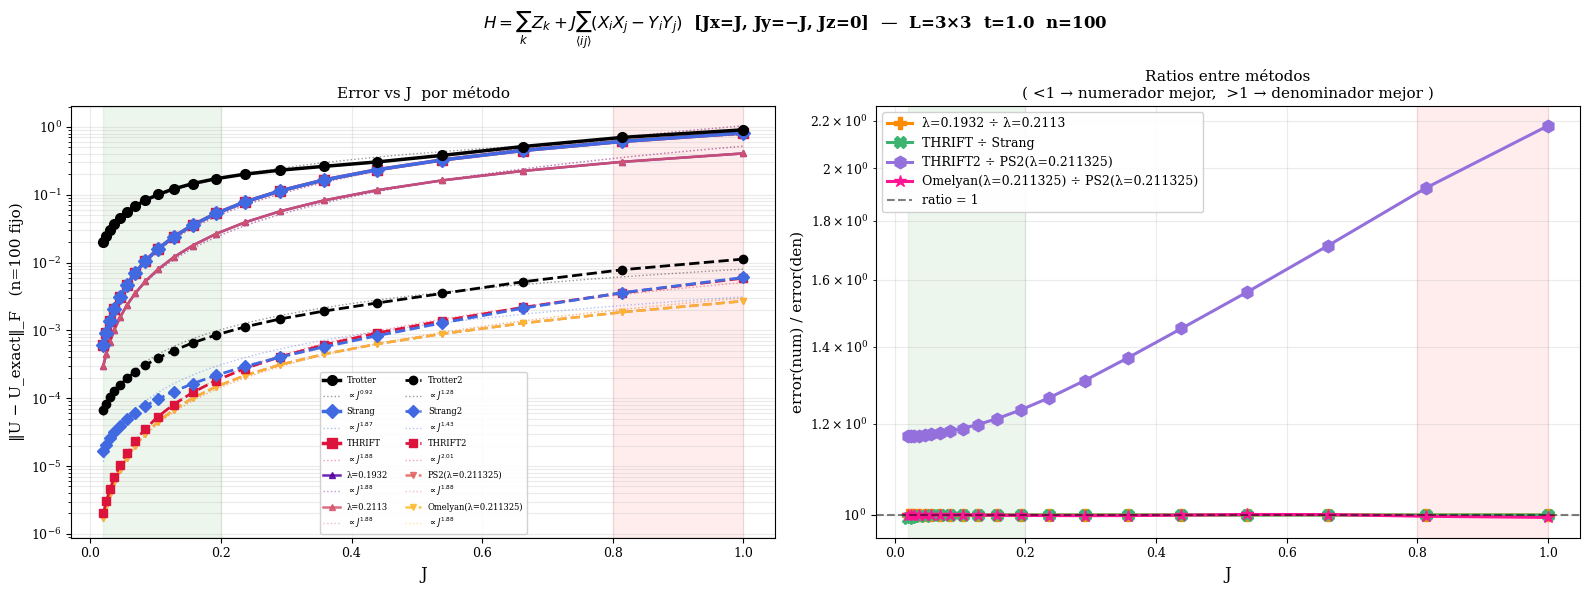

In [4]:
# ============================================================
# Barrido de J — versión mínima (solo error a dt fijo + ratios)
# ============================================================

import os, json, time
import numpy as np
from scipy.linalg import expm
from concurrent.futures import ThreadPoolExecutor, as_completed
import matplotlib.pyplot as plt


def _compute_error(n, method, lam, Jx, Jy, L, t_val, U_exact):
    system  = HeisenbergAniso2D(L, Jx, Jy, 0.0)
    cache   = GateCache()
    evolver = Evolver(system, t_val, cache)
    U       = evolver.compute_unitary(n, method, lam=lam)
    return float(np.linalg.norm(U - U_exact, 'fro'))

def _worker(n, mkey, mname, mlam, Jx, Jy, L, t_val, U_exact):
    err = _compute_error(n, mkey, mlam, Jx, Jy, L, t_val, U_exact)
    return (mname, err)

def _serial(obj):
    if isinstance(obj, np.ndarray):                return obj.tolist()
    if isinstance(obj, dict):                      return {k: _serial(v) for k, v in obj.items()}
    if isinstance(obj, list):                      return [_serial(x) for x in obj]
    if isinstance(obj, (np.floating, np.integer)): return obj.item()
    return obj


# -----------------------------------------------------------------------
# EXPERIMENTO — solo n_fixed, sin barrido de convergencia
# -----------------------------------------------------------------------

def run_J_sweep(
    L           = 3,
    J_values    = None,
    t           = 1.0,
    n_fixed     = 50,
    results_dir = 'results',
    lambda_values = None,
    lam_ps2     = 0.211325,
    lam_omelyan = 0.211325,
    n_workers   = None,
):
    if J_values is None:
        J_values = np.geomspace(0.02, 1.0, 10)
    J_values = np.array(J_values)

    if lambda_values is None:
        lambda_values = {'λ=0.1932': 0.193183, 'λ=0.2113': 0.211325}

    if n_workers is None:
        n_workers = os.cpu_count()

    name_ps2  = f'ULam2(λ={lam_ps2})'
    name_oml  = f'OG(λ={lam_omelyan})'
    lam_names = list(lambda_values.keys())

    all_methods = (
        ['LTS', 'PS', 'THRIFT']
        + lam_names
        + ['LTS2', 'PS2', 'THRIFT2']
        + [name_ps2, name_oml]
    )
    method_keys = (
        ['lts', 'ps', 'thrift']
        + ['u_lambda'] * len(lambda_values)
        + ['lts2', 'ps2', 'thrift2']
        + ['u_lambda2', 'og']
    )
    method_lams = (
        [None, None, None]
        + list(lambda_values.values())
        + [None, None, None]
        + [lam_ps2, lam_omelyan]
    )

    # ── Ratios ────────────────────────────────────────────────────────
    ratio_defs = []
    if len(lam_names) >= 2:
        ratio_defs.append((f'{lam_names[0]} ÷ {lam_names[1]}',
                           lam_names[0], lam_names[1]))
    ratio_defs += [
        ('THRIFT ÷ PS',          'THRIFT',  'PS'),
        (f'THRIFT2 ÷ {name_ps2}',    'THRIFT2', name_ps2),
        (f'{name_oml} ÷ {name_ps2}', name_oml,  name_ps2),
    ]
    ratio_names = [r[0] for r in ratio_defs]

    # ── Checkpoint ────────────────────────────────────────────────────
    run_dir   = os.path.join(results_dir, f"Jsweep_XXMYY_L{L}_t{t}_n{n_fixed}")
    os.makedirs(run_dir, exist_ok=True)
    ckpt_path = os.path.join(run_dir, 'data.json')

    errors_fixed = {m: [] for m in all_methods}
    ratios_fixed = {r: [] for r in ratio_names}
    start_idx    = 0

    if os.path.exists(ckpt_path):
        with open(ckpt_path) as f:
            saved = json.load(f)
        if saved.get('all_methods') == all_methods:
            done = len(saved['errors_fixed'][all_methods[0]])
            if done > 0:
                print(f"[checkpoint] Retomando desde J[{done}] "
                      f"({done}/{len(J_values)} completados)")
                errors_fixed = saved['errors_fixed']
                ratios_fixed = saved.get('ratios_fixed',
                                         {r: [] for r in ratio_names})
                start_idx = done
        else:
            print("[checkpoint] Métodos cambiaron — empezando desde cero")

    n_methods = len(all_methods)
    print(f"\n{'='*60}")
    print(f"H = Σ Z_k  +  J Σ (Xi Xj − Yi Yj)   [Jx=J, Jy=-J, Jz=0]")
    print(f"L={L}  t={t}  n_fixed={n_fixed}  workers={n_workers}")
    print(f"J ∈ [{J_values[0]:.4f}, {J_values[-1]:.4f}]  ({len(J_values)} puntos)")
    print(f"Métodos ({n_methods}): {all_methods}")
    print(f"Ratios  ({len(ratio_names)}): {ratio_names}")
    print(f"Tareas por J: {n_methods}   ← solo n_fixed, sin barrido")
    print(f"{'='*60}\n")

    t_total = time.time()

    for j_idx in range(start_idx, len(J_values)):
        J  = J_values[j_idx]
        Jx, Jy = J, -J

        print(f"[{j_idx+1}/{len(J_values)}]  J={J:.5f}", end='  ', flush=True)

        # U_exact
        system  = HeisenbergAniso2D(L, Jx, Jy, 0.0)
        U_exact = expm(-1j * system.build_hamiltonian() * t)

        # ── n_methods tareas en paralelo (una por método) ─────────────
        with ThreadPoolExecutor(max_workers=n_workers) as pool:
            futs = {
                pool.submit(_worker, n_fixed, mkey, mname, mlam,
                            Jx, Jy, L, t, U_exact): mname
                for mkey, mname, mlam in zip(method_keys, all_methods, method_lams)
            }
            for fut in as_completed(futs):
                mname, err = fut.result()
                errors_fixed[mname].append(err)

        # ── Ratios ────────────────────────────────────────────────────
        for rname, num, den in ratio_defs:
            e_num = errors_fixed[num][-1]
            e_den = errors_fixed[den][-1]
            val   = (e_num / e_den
                     if e_den > 0 and np.isfinite(e_num) and np.isfinite(e_den)
                     else float('nan'))
            ratios_fixed[rname].append(val)

        print("err: " + "  ".join(f"{m}={errors_fixed[m][-1]:.3e}"
                                   for m in all_methods))
        print("      ratios: " + "  ".join(f"{rn}={ratios_fixed[rn][-1]:.3f}"
                                            for rn in ratio_names))
        print(f"      acum: {time.time()-t_total:.1f}s\n", flush=True)

        # ── Checkpoint ───────────────────────────────────────────────
        ckpt = dict(
            hamiltonian   = 'sum_k Zk + J·sum_ij(XiXj - YiYj)',
            L=L, t=t, n_fixed=n_fixed,
            J_values      = J_values.tolist(),
            all_methods   = all_methods,
            lambda_values = lambda_values,
            lam_ps2       = lam_ps2,
            lam_omelyan   = lam_omelyan,
            errors_fixed  = errors_fixed,
            ratio_defs    = [[r[0], r[1], r[2]] for r in ratio_defs],
            ratios_fixed  = ratios_fixed,
        )
        with open(ckpt_path, 'w') as f:
            json.dump(_serial(ckpt), f, indent=2)

    print(f"Total: {time.time()-t_total:.1f}s  →  {ckpt_path}")
    with open(ckpt_path) as f:
        return json.load(f), run_dir


# -----------------------------------------------------------------------
# LOAD
# -----------------------------------------------------------------------

def load_J_sweep(run_dir):
    with open(os.path.join(run_dir, 'data.json')) as f:
        data = json.load(f)
    print(f"[load] L={data['L']}  t={data['t']}  n_fixed={data['n_fixed']}  "
          f"J ∈ [{min(data['J_values']):.4f}, {max(data['J_values']):.4f}]  "
          f"({len(data['J_values'])} puntos)")
    print(f"       métodos: {data['all_methods']}")
    print(f"       ratios:  {list(data['ratios_fixed'].keys())}")
    return data


# -----------------------------------------------------------------------
# AJUSTE LEY DE POTENCIA
# -----------------------------------------------------------------------

def fit_power_law(J_values, errors):
    J, err = np.array(J_values), np.array(errors)
    valid  = (J > 0) & (err > 0) & np.isfinite(err)
    if valid.sum() < 2:
        return None
    n, log_a = np.polyfit(np.log(J[valid]), np.log(err[valid]), 1)
    a = np.exp(log_a)
    J_fit = np.linspace(J[valid].min(), J[valid].max(), 200)
    return a, n, J_fit, a * J_fit ** n

def print_fit_summary(J_values, all_methods, errors_fixed):
    print(f"\n{'─'*55}")
    print(f"  error = a · J^n   (ajuste log-log a n_fixed fijo)")
    print(f"{'─'*55}")
    print(f"  {'Método':<33}  {'a':>10}  {'n':>6}")
    print(f"{'─'*55}")
    for m in all_methods:
        r = fit_power_law(J_values, errors_fixed[m])
        if r:
            print(f"  {m:<33}  {r[0]:>10.4e}  {r[1]:>6.3f}")
        else:
            print(f"  {m:<33}  {'N/A':>10}  {'N/A':>6}")
    print(f"{'─'*55}\n")


# -----------------------------------------------------------------------
# PLOT — 2 paneles: error vs J | ratios vs J
# -----------------------------------------------------------------------

def plot_J_sweep(data, save_fig=True, show=True, out_dir='figures'):
    J_values     = np.array(data['J_values'])
    all_methods  = data['all_methods']
    errors_fixed = data['errors_fixed']
    ratios_fixed = data.get('ratios_fixed', {})
    L, t, n_fixed = data['L'], data['t'], data['n_fixed']

    n_done   = len(errors_fixed[all_methods[0]])
    J_values = J_values[:n_done]

    # ── Estilos métodos ───────────────────────────────────────────────
    fixed_styles = {
        'LTS':  dict(color='black',     marker='o', lw=2.5, ms=7, ls='-',  zorder=10),
        'PS':   dict(color='royalblue', marker='D', lw=2.5, ms=7, ls='-',  zorder=9),
        'THRIFT':   dict(color='crimson',   marker='s', lw=2.5, ms=7, ls='-',  zorder=8),
        'LTS2': dict(color='black',     marker='o', lw=2.0, ms=6, ls='--', zorder=10),
        'PS2':  dict(color='royalblue', marker='D', lw=2.0, ms=6, ls='--', zorder=9),
        'THRIFT2':  dict(color='crimson',   marker='s', lw=2.0, ms=6, ls='--', zorder=8),
    }
    lam_1st = [m for m in all_methods
               if m not in fixed_styles
               and not any(x in m for x in ['LTS2','PS2','THRIFT2','ULam2','OG'])]
    for i, m in enumerate(lam_1st):
        c = plt.cm.plasma(np.linspace(0.15, 0.55, max(len(lam_1st), 1))[i])
        fixed_styles[m] = dict(color=c, marker='^', lw=1.8, ms=5, ls='-',
                               zorder=7, alpha=0.85)
    lam_2nd = [m for m in all_methods if 'ULam2' in m or 'OG' in m]
    for i, m in enumerate(lam_2nd):
        c = plt.cm.plasma(np.linspace(0.60, 0.85, max(len(lam_2nd), 1))[i])
        fixed_styles[m] = dict(color=c, marker='v', lw=1.8, ms=5, ls='--',
                               zorder=7, alpha=0.85)
    styles = fixed_styles

    # ── Estilos ratios ────────────────────────────────────────────────
    _rc = ['darkorange', 'mediumseagreen', 'mediumpurple', 'deeppink']
    _rm = ['P', 'X', 'h', '*']
    ratio_styles = {rn: dict(color=_rc[i%4], marker=_rm[i%4],
                              lw=2.2, ms=9, ls='-')
                    for i, rn in enumerate(ratios_fixed.keys())}

    def _shade(ax):
        ax.axvspan(J_values[0], min(0.2, J_values[-1]), alpha=0.07, color='green')
        if J_values[-1] > 0.8:
            ax.axvspan(0.8, J_values[-1], alpha=0.07, color='red')

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle(
        r'$H = \sum_k Z_k + J\sum_{\langle ij\rangle}(X_iX_j - Y_iY_j)$'
        f'  [Jx=J, Jy=−J, Jz=0]  —  L={L}×{L}  t={t}  n={n_fixed}',
        fontsize=12, fontweight='bold'
    )

    # Panel izquierdo — error vs J por método
    ax = axes[0]
    for name in all_methods:
        st = styles[name]
        kw = dict(color=st['color'], marker=st['marker'], lw=st['lw'],
                  ms=st['ms'], linestyle=st['ls'], zorder=st['zorder'])
        if 'alpha' in st: kw['alpha'] = st['alpha']
        ax.semilogy(J_values, errors_fixed[name], label=name, **kw)
        r = fit_power_law(J_values, errors_fixed[name])
        if r:
            ax.plot(r[2], r[3], ':', lw=1.0, color=st['color'], alpha=0.4,
                    label=rf'$\propto J^{{{r[1]:.2f}}}$')
    _shade(ax)
    ax.set_xlabel('J', fontsize=12)
    ax.set_ylabel(f'‖U − U_exact‖_F   (n={n_fixed} fijo)', fontsize=11)
    ax.set_title('Error vs J  por método', fontsize=11)
    ax.grid(True, which='both', alpha=0.25)
    ax.legend(fontsize=6, ncol=2, framealpha=0.9)
    print_fit_summary(J_values, all_methods, errors_fixed)

    # Panel derecho — ratios vs J
    ax = axes[1]
    for rn, rvals in ratios_fixed.items():
        rv = np.array(rvals[:n_done])
        st = ratio_styles[rn]
        ax.semilogy(J_values, rv, label=rn,
                    color=st['color'], marker=st['marker'],
                    lw=st['lw'], ms=st['ms'], linestyle=st['ls'])
    ax.axhline(1.0, color='black', ls='--', lw=1.5, alpha=0.5,
               label='ratio = 1')
    _shade(ax)
    ax.set_xlabel('J', fontsize=12)
    ax.set_ylabel('error(num) / error(den)', fontsize=11)
    ax.set_title('Ratios entre métodos\n'
                 '( <1 → numerador mejor,  >1 → denominador mejor )',
                 fontsize=11)
    ax.grid(True, which='both', alpha=0.25)
    ax.legend(fontsize=9, framealpha=0.9)

    plt.tight_layout()
    if save_fig:
        os.makedirs(out_dir, exist_ok=True)
        fname = os.path.join(out_dir, f'Jsweep_L{L}_t{t}_n{n_fixed}.png')
        plt.savefig(fname, dpi=150, bbox_inches='tight')
        print(f"[plot] {fname}")
    if show:
        plt.show()
    return fig


# -----------------------------------------------------------------------
# EJECUTAR
# -----------------------------------------------------------------------

if __name__ == '__main__':
    data, run_dir = run_J_sweep(
        L           = 3,
        J_values    = np.geomspace(0.02, 1.0, 20),
        t           = 1.0,
        n_fixed     = 100,
        lam_ps2     = 0.211325,
        lam_omelyan = 0.211325,
        n_workers   = None,
    )
    plot_J_sweep(data)


EXPERIMENTO: α(N)   error = mean_k ‖(U-Uexact)|ψ_k⟩‖
H = Σ Zk + J Σ (XiXj − YiYj)   [Jx=J, Jy=−J, Jz=0]
L=2  dim=16  t=1.0  n_states=10  seed=42
J ∈ [0.0200, 1.0000]  (20 puntos)
N ∈ [5, 10, 20, 40, 80, 160, 320, 640, 1280]
Métodos (9): ['Trotter', 'Strang', 'THRIFT', 'λ=0.2113', 'Trotter2', 'Strang2', 'THRIFT2', 'PS2(λ=0.211325)', 'Omelyan(λ=0.211325)']
workers: 12

[N=    5  dt=0.200000]  (1/9)
  J[ 5/20]=0.0456  Trotter=2.20e-02±4.6e-03  Strang=1.90e-03±4.1e-04  THRIFT=1.07e-03±2.9e-04 ...
  J[10/20]=0.1276  Trotter=5.97e-02±1.2e-02  Strang=9.66e-03±2.1e-03  THRIFT=8.26e-03±2.2e-03 ...
  J[15/20]=0.3572  Trotter=1.33e-01±2.6e-02  Strang=6.42e-02±1.7e-02  THRIFT=6.03e-02±1.6e-02 ...
  J[20/20]=1.0000  Trotter=3.68e-01±7.7e-02  Strang=3.40e-01±9.8e-02  THRIFT=3.27e-01±8.4e-02 ...
  → α: Trotter=0.874  Strang=1.648  THRIFT=1.917  λ=0.2113=1.915  Trotter2=1.221  Strang2=1.295  THRIFT2=1.976  PS2(λ=0.211325)=1.888  Omelyan(λ=0.211325)=1.889
  acum: 1.0s

[N=   10  dt=0.100000]  (2/9)
  

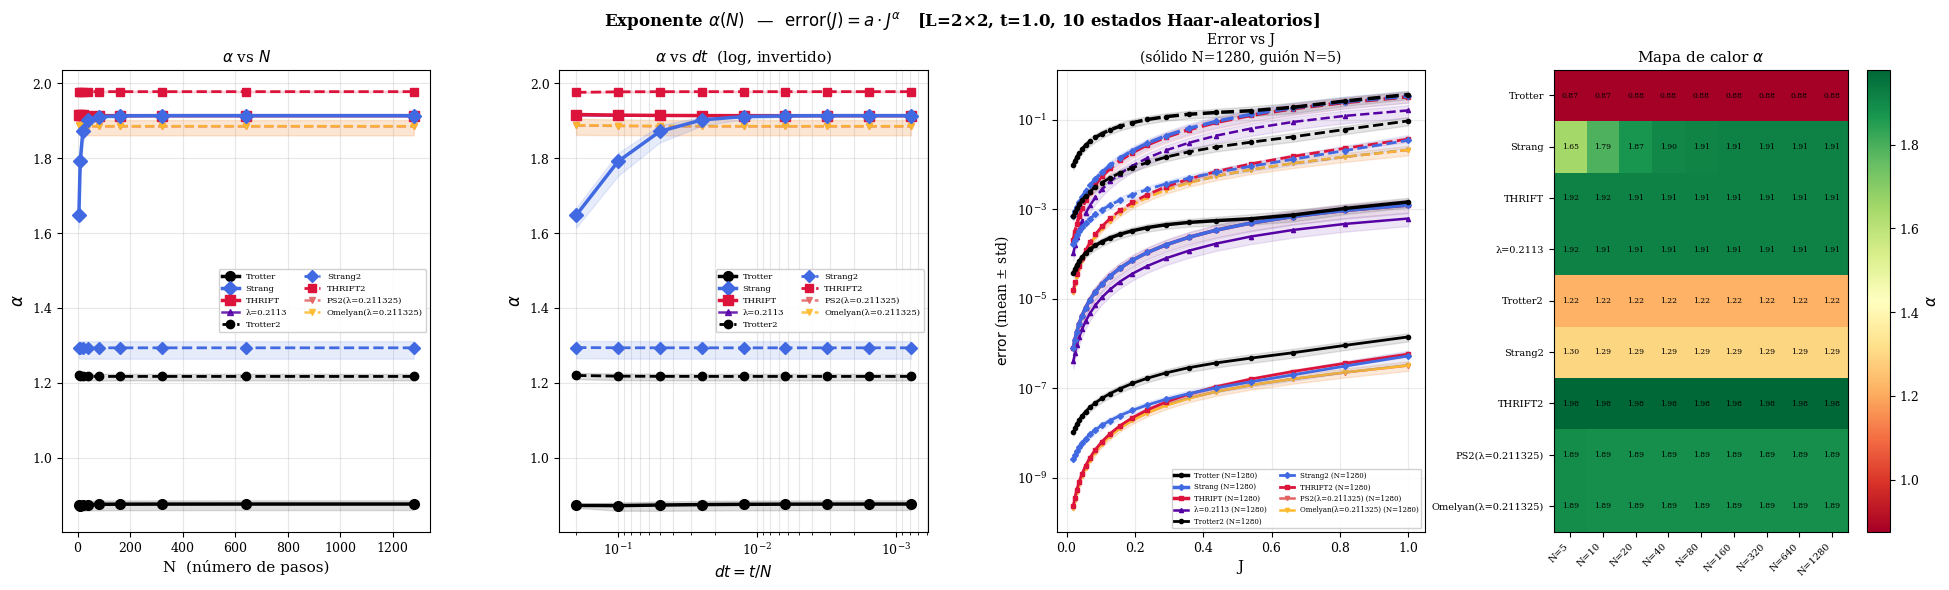

In [5]:
# ============================================================
# alpha_vs_N — estados aleatorios + error con incertidumbre
# ============================================================

import os, json, time
import numpy as np
from scipy.linalg import expm
from concurrent.futures import ThreadPoolExecutor, as_completed
import matplotlib.pyplot as plt


# -----------------------------------------------------------------------
# helpers
# -----------------------------------------------------------------------

def _make_random_states(dim, n_states, rng):
    """Haar-random states: columnas normalizadas de shape (dim, n_states)."""
    z = (rng.standard_normal((dim, n_states))
         + 1j * rng.standard_normal((dim, n_states)))
    z /= np.linalg.norm(z, axis=0)
    return z

def _compute_error_states(n, method, lam, Jx, Jy, L, t_val, U_exact, states):
    """
    Devuelve (mean, std) del error ‖(U-U_exact)|ψ_k⟩‖ sobre los estados.
    """
    system  = HeisenbergAniso2D(L, Jx, Jy, 0.0)
    cache   = GateCache()
    evolver = Evolver(system, t_val, cache)
    U       = evolver.compute_unitary(n, method, lam=lam)
    errs    = np.linalg.norm((U - U_exact) @ states, axis=0)  # (n_states,)
    return float(errs.mean()), float(errs.std())

def _worker(n, mkey, mname, mlam, Jx, Jy, L, t_val, U_exact, states):
    mean, std = _compute_error_states(n, mkey, mlam, Jx, Jy, L, t_val, U_exact, states)
    return mname, mean, std

def _serial(obj):
    if isinstance(obj, np.ndarray):                return obj.tolist()
    if isinstance(obj, dict):                      return {k: _serial(v) for k, v in obj.items()}
    if isinstance(obj, list):                      return [_serial(x) for x in obj]
    if isinstance(obj, (np.floating, np.integer)): return obj.item()
    return obj

def fit_power_law_alpha(J_values, errors):
    """Ajuste error = a·J^α en log-log. Devuelve α o nan."""
    J, err = np.array(J_values), np.array(errors)
    valid  = (J > 0) & (err > 0) & np.isfinite(err)
    if valid.sum() < 3:
        return float('nan')
    alpha, _ = np.polyfit(np.log(J[valid]), np.log(err[valid]), 1)
    return float(alpha)


# -----------------------------------------------------------------------
# GUARDADO
# -----------------------------------------------------------------------

def save_results(data, run_dir):
    """
    Guarda en run_dir:
      data.json       — experimento completo
      alpha_table.csv — α(método, N)
      errors_raw.npz  — arrays (métodos × N × J) para mean y std
    """
    os.makedirs(run_dir, exist_ok=True)

    json_path = os.path.join(run_dir, 'data.json')
    with open(json_path, 'w') as f:
        json.dump(_serial(data), f, indent=2)
    print(f"[save] JSON         → {json_path}")

    all_methods = data['all_methods']
    n_values    = data['n_values']
    alpha_data  = data['alpha_data']
    n_done      = len(alpha_data[all_methods[0]])

    csv_path = os.path.join(run_dir, 'alpha_table.csv')
    with open(csv_path, 'w') as f:
        f.write('method,' + ','.join(f'N={n}' for n in n_values[:n_done]) + '\n')
        for m in all_methods:
            row = ','.join(
                f'{alpha_data[m][i]:.8f}' if np.isfinite(alpha_data[m][i]) else 'nan'
                for i in range(n_done)
            )
            f.write(f'{m},{row}\n')
    print(f"[save] alpha_table  → {csv_path}")

    J_values    = np.array(data['J_values'])
    mean_matrix = np.full((len(all_methods), n_done, len(J_values)), np.nan)
    std_matrix  = np.full((len(all_methods), n_done, len(J_values)), np.nan)
    for i, m in enumerate(all_methods):
        for j in range(n_done):
            means = data['errors_mean'][m][j]
            stds  = data['errors_std'][m][j]
            mean_matrix[i, j, :len(means)] = means
            std_matrix [i, j, :len(stds) ] = stds

    npz_path = os.path.join(run_dir, 'errors_raw.npz')
    np.savez(npz_path,
             mean_matrix = mean_matrix,
             std_matrix  = std_matrix,
             methods     = np.array(all_methods),
             n_values    = np.array(n_values[:n_done]),
             J_values    = J_values,
             L           = np.array(data['L']),
             t           = np.array(data['t']),
             n_states    = np.array(data['n_states']))
    print(f"[save] errors_raw   → {npz_path}")
    print(f"       shape = {mean_matrix.shape}  (métodos × N × J)")
    return json_path, csv_path, npz_path


# -----------------------------------------------------------------------
# LOAD
# -----------------------------------------------------------------------

def load_results(run_dir):
    with open(os.path.join(run_dir, 'data.json')) as f:
        data = json.load(f)
    npz  = np.load(os.path.join(run_dir, 'errors_raw.npz'), allow_pickle=True)
    meta = dict(
        methods      = list(npz['methods']),
        n_values     = npz['n_values'].tolist(),
        J_values     = npz['J_values'],
        L            = int(npz['L']),
        t            = float(npz['t']),
        n_states     = int(npz['n_states']),
        mean_matrix  = npz['mean_matrix'],   # (métodos, N, J)
        std_matrix   = npz['std_matrix'],
    )
    print(f"[load] L={meta['L']}  t={meta['t']}  n_states={meta['n_states']}")
    print(f"       N ∈ {meta['n_values']}")
    print(f"       J ∈ [{meta['J_values'].min():.4f}, {meta['J_values'].max():.4f}]")
    print(f"       métodos: {meta['methods']}")
    return data, meta


# -----------------------------------------------------------------------
# EXPERIMENTO
# -----------------------------------------------------------------------

def run_alpha_vs_N(
    L             = 2,
    J_values      = None,
    t             = 1.0,
    n_values      = None,
    n_states      = 10,          # estados Haar-aleatorios por punto (J, N)
    seed          = 42,          # semilla para reproducibilidad
    results_dir   = 'results',
    lambda_values = None,        # solo λ=0.2113 por defecto
    lam_ps2       = 0.211325,
    lam_omelyan   = 0.211325,
    n_workers     = None,
):
    # ── defaults ──────────────────────────────────────────────────────
    if J_values is None:
        J_values = np.geomspace(0.02, 1.0, 20)
    J_values = np.array(J_values)

    if n_values is None:
        n_values = [5, 10, 20, 40, 80, 160, 320, 640, 1280]
    n_values = list(n_values)

    if lambda_values is None:
        lambda_values = {'λ=0.2113': 0.211325}   # solo uno

    if n_workers is None:
        n_workers = os.cpu_count()

    name_ps2  = f'ULam2(λ={lam_ps2})'
    name_oml  = f'OG(λ={lam_omelyan})'
    lam_names = list(lambda_values.keys())

    all_methods = (
        ['LTS', 'PS', 'THRIFT']
        + lam_names
        + ['LTS2', 'PS2', 'THRIFT2']
        + [name_ps2, name_oml]
    )
    method_keys = (
        ['lts', 'ps', 'thrift']
        + ['u_lambda'] * len(lambda_values)
        + ['lts2', 'ps2', 'thrift2']
        + ['u_lambda2', 'og']
    )
    method_lams = (
        [None, None, None]
        + list(lambda_values.values())
        + [None, None, None]
        + [lam_ps2, lam_omelyan]
    )

    run_dir   = os.path.join(results_dir,
                             f"alpha_vs_N_L{L}_t{t}_Nmin{n_values[0]}_Nmax{n_values[-1]}"
                             f"_ns{n_states}")
    os.makedirs(run_dir, exist_ok=True)
    ckpt_path = os.path.join(run_dir, 'data.json')

    # estructuras de datos: [método][n_idx] = list of floats (one per J)
    alpha_data  = {m: [] for m in all_methods}
    errors_mean = {m: [] for m in all_methods}
    errors_std  = {m: [] for m in all_methods}
    start_n_idx = 0

    if os.path.exists(ckpt_path):
        with open(ckpt_path) as f:
            saved = json.load(f)
        if (saved.get('all_methods') == all_methods
                and saved.get('n_values') == n_values
                and saved.get('n_states') == n_states
                and saved.get('seed')     == seed):
            alpha_data  = saved['alpha_data']
            errors_mean = saved['errors_mean']
            errors_std  = saved['errors_std']
            start_n_idx = len(alpha_data[all_methods[0]])
            if start_n_idx > 0:
                print(f"[checkpoint] Retomando desde N[{start_n_idx}] "
                      f"({start_n_idx}/{len(n_values)} completados)")
        else:
            print("[checkpoint] Parámetros cambiaron — empezando desde cero")

    # estados aleatorios: mismos para TODOS los métodos y todos los puntos
    # generados una sola vez con seed fija → reproducible
    dim = 2 ** (L * L)
    rng = np.random.default_rng(seed)
    states = _make_random_states(dim, n_states, rng)   # (dim, n_states)

    print(f"\n{'='*65}")
    print(f"EXPERIMENTO: α(N)   error = mean_k ‖(U-Uexact)|ψ_k⟩‖")
    print(f"H = Σ Zk + J Σ (XiXj − YiYj)   [Jx=J, Jy=−J, Jz=0]")
    print(f"L={L}  dim={dim}  t={t}  n_states={n_states}  seed={seed}")
    print(f"J ∈ [{J_values[0]:.4f}, {J_values[-1]:.4f}]  ({len(J_values)} puntos)")
    print(f"N ∈ {n_values}")
    print(f"Métodos ({len(all_methods)}): {all_methods}")
    print(f"workers: {n_workers}")
    print(f"{'='*65}\n")

    t_total = time.time()

    for n_idx in range(start_n_idx, len(n_values)):
        N  = n_values[n_idx]
        dt = t / N
        print(f"[N={N:5d}  dt={dt:.6f}]  ({n_idx+1}/{len(n_values)})", flush=True)

        # acumuladores para este N
        means_for_N = {m: [] for m in all_methods}
        stds_for_N  = {m: [] for m in all_methods}

        for j_idx, J in enumerate(J_values):
            Jx, Jy  = J, -J
            system  = HeisenbergAniso2D(L, Jx, Jy, 0.0)
            U_exact = expm(-1j * system.build_hamiltonian() * t)

            # paralelismo simple: un thread por método, para este (N, J)
            with ThreadPoolExecutor(max_workers=n_workers) as pool:
                futs = {
                    pool.submit(_worker, N, mkey, mname, mlam,
                                Jx, Jy, L, t, U_exact, states): mname
                    for mkey, mname, mlam in zip(method_keys, all_methods, method_lams)
                }
                for fut in as_completed(futs):
                    mname, mean, std = fut.result()
                    means_for_N[mname].append(mean)
                    stds_for_N [mname].append(std)

            if (j_idx + 1) % 5 == 0 or j_idx == len(J_values) - 1:
                print(f"  J[{j_idx+1:2d}/{len(J_values)}]={J:.4f}  "
                      + "  ".join(
                          f"{m}={means_for_N[m][-1]:.2e}±{stds_for_N[m][-1]:.1e}"
                          for m in all_methods[:3])
                      + " ...", flush=True)

        # ajuste α sobre la curva de medias
        for m in all_methods:
            α = fit_power_law_alpha(J_values, means_for_N[m])
            alpha_data [m].append(α)
            errors_mean[m].append(means_for_N[m])
            errors_std [m].append(stds_for_N [m])

        print(f"  → α: " + "  ".join(f"{m}={alpha_data[m][-1]:.3f}"
                                      for m in all_methods))
        print(f"  acum: {time.time()-t_total:.1f}s\n", flush=True)

        # checkpoint
        ckpt = dict(
            hamiltonian   = 'sum_k Zk + J·sum_ij(XiXj - YiYj)',
            L=L, t=t, n_states=n_states, seed=seed,
            J_values      = J_values.tolist(),
            n_values      = n_values,
            all_methods   = all_methods,
            lambda_values = lambda_values,
            lam_ps2       = lam_ps2,
            lam_omelyan   = lam_omelyan,
            alpha_data    = alpha_data,
            errors_mean   = errors_mean,
            errors_std    = errors_std,
        )
        with open(ckpt_path, 'w') as f:
            json.dump(_serial(ckpt), f, indent=2)

    print(f"Total: {time.time()-t_total:.1f}s")
    with open(ckpt_path) as f:
        data = json.load(f)
    save_results(data, run_dir)
    return data, run_dir


# -----------------------------------------------------------------------
# ESTILOS
# -----------------------------------------------------------------------

def _build_styles(all_methods):
    fixed_styles = {
        'LTS':  dict(color='black',     marker='o', lw=2.5, ms=7, ls='-',  zorder=10),
        'PS':   dict(color='royalblue', marker='D', lw=2.5, ms=7, ls='-',  zorder=9),
        'THRIFT':   dict(color='crimson',   marker='s', lw=2.5, ms=7, ls='-',  zorder=8),
        'LTS2': dict(color='black',     marker='o', lw=2.0, ms=6, ls='--', zorder=10),
        'PS2':  dict(color='royalblue', marker='D', lw=2.0, ms=6, ls='--', zorder=9),
        'THRIFT2':  dict(color='crimson',   marker='s', lw=2.0, ms=6, ls='--', zorder=8),
    }
    lam_1st = [m for m in all_methods
               if m not in fixed_styles
               and not any(x in m for x in ['LTS2','PS2','THRIFT2','ULam2','OG'])]
    for i, m in enumerate(lam_1st):
        c = plt.cm.plasma(np.linspace(0.15, 0.55, max(len(lam_1st), 1))[i])
        fixed_styles[m] = dict(color=c, marker='^', lw=1.8, ms=5, ls='-', zorder=7, alpha=0.85)
    lam_2nd = [m for m in all_methods if 'ULam2' in m or 'OG' in m]
    for i, m in enumerate(lam_2nd):
        c = plt.cm.plasma(np.linspace(0.60, 0.85, max(len(lam_2nd), 1))[i])
        fixed_styles[m] = dict(color=c, marker='v', lw=1.8, ms=5, ls='--', zorder=7, alpha=0.85)
    return fixed_styles


# -----------------------------------------------------------------------
# PLOT
# -----------------------------------------------------------------------

def plot_alpha_vs_N(data, save_fig=True, show=True, out_dir='figures'):
    n_values    = np.array(data['n_values'])
    all_methods = data['all_methods']
    alpha_data  = data['alpha_data']
    errors_mean = data['errors_mean']
    errors_std  = data['errors_std']
    J_values    = np.array(data['J_values'])
    L, t        = data['L'], data['t']
    n_states    = data.get('n_states', '?')

    n_done    = len(alpha_data[all_methods[0]])
    n_values  = n_values[:n_done]
    dt_values = t / n_values
    styles    = _build_styles(all_methods)

    # ── tabla consola ─────────────────────────────────────────────────
    print(f"\n{'─'*70}")
    print(f"  α(N)  [L={L}, t={t}, n_states={n_states}]")
    print(f"{'─'*70}")
    print(f"  {'Método':<30}" + "".join(f"  N={n:>5}" for n in n_values))
    print(f"{'─'*70}")
    for m in all_methods:
        row = "".join(
            f"  {float(alpha_data[m][i]):>6.3f}" if np.isfinite(float(alpha_data[m][i]))
            else f"  {'nan':>6}"
            for i in range(n_done)
        )
        print(f"  {m:<30}{row}")
    print(f"{'─'*70}\n")

    # ── figura: 4 paneles ─────────────────────────────────────────────
    # [ α vs N ] [ α vs dt ] [ error vs J (un N) ] [ heatmap α ]
    fig = plt.figure(figsize=(24, 6))
    gs  = fig.add_gridspec(1, 4, wspace=0.35)
    ax0 = fig.add_subplot(gs[0])
    ax1 = fig.add_subplot(gs[1])
    ax2 = fig.add_subplot(gs[2])
    ax3 = fig.add_subplot(gs[3])

    fig.suptitle(
        r'Exponente $\alpha(N)$  —  $\mathrm{error}(J)=a\cdot J^\alpha$'
        f'   [L={L}×{L}, t={t}, {n_states} estados Haar-aleatorios]',
        fontsize=12, fontweight='bold'
    )

    # helper: dibuja α vs xvals con banda de incertidumbre en α
    # La incertidumbre en α se propaga desde el std de los errores:
    # hacemos un fit adicional sobre (mean ± std) para obtener α_hi, α_lo
    def _alpha_band(m):
        alphas, a_lo, a_hi = [], [], []
        for ni in range(n_done):
            means = np.array(errors_mean[m][ni], dtype=float)
            stds  = np.array(errors_std [m][ni], dtype=float)
            alphas.append(float(alpha_data[m][ni]))
            # fit sobre mean + std  y  mean - std  (clip a >0)
            hi = fit_power_law_alpha(J_values, np.maximum(means + stds, 1e-300))
            lo = fit_power_law_alpha(J_values, np.maximum(means - stds, 1e-300))
            a_hi.append(hi if np.isfinite(hi) else float(alpha_data[m][ni]))
            a_lo.append(lo if np.isfinite(lo) else float(alpha_data[m][ni]))
        return (np.array(alphas, dtype=float),
                np.array(a_lo,   dtype=float),
                np.array(a_hi,   dtype=float))

    # ── Panel 0: α vs N ───────────────────────────────────────────────
    for m in all_methods:
        alphas, a_lo, a_hi = _alpha_band(m)
        st = styles[m]
        kw = dict(color=st['color'], marker=st['marker'], lw=st['lw'],
                  ms=st['ms'], linestyle=st['ls'], zorder=st['zorder'],
                  label=m)
        if 'alpha' in st: kw['alpha'] = st['alpha']
        ax0.plot(n_values, alphas, **kw)
        ax0.fill_between(n_values, a_lo, a_hi,
                         color=st['color'], alpha=0.12, zorder=st['zorder']-1)
    ax0.set_xlabel('N  (número de pasos)', fontsize=11)
    ax0.set_ylabel(r'$\alpha$', fontsize=12)
    ax0.set_title(r'$\alpha$ vs $N$', fontsize=11)
    ax0.grid(True, which='both', alpha=0.3)
    ax0.legend(fontsize=6, ncol=2, framealpha=0.9)

    # ── Panel 1: α vs dt (log, invertido) ────────────────────────────
    for m in all_methods:
        alphas, a_lo, a_hi = _alpha_band(m)
        st = styles[m]
        kw = dict(color=st['color'], marker=st['marker'], lw=st['lw'],
                  ms=st['ms'], linestyle=st['ls'], zorder=st['zorder'],
                  label=m)
        if 'alpha' in st: kw['alpha'] = st['alpha']
        ax1.plot(dt_values, alphas, **kw)
        ax1.fill_between(dt_values, a_lo, a_hi,
                         color=st['color'], alpha=0.12, zorder=st['zorder']-1)
    ax1.set_xscale('log')
    ax1.invert_xaxis()
    ax1.set_xlabel(r'$dt = t/N$', fontsize=11)
    ax1.set_ylabel(r'$\alpha$', fontsize=12)
    ax1.set_title(r'$\alpha$ vs $dt$  (log, invertido)', fontsize=11)
    ax1.grid(True, which='both', alpha=0.3)
    ax1.legend(fontsize=6, ncol=2, framealpha=0.9)

    # ── Panel 2: error vs J para N grande y N pequeño ─────────────────
    # muestra el spread mean ± std directamente en la curva de error
    ni_small = 0                      # N más pequeño
    ni_large = n_done - 1             # N más grande
    for ni, ls, lbl in [(ni_small, '--', f'N={n_values[ni_small]}'),
                        (ni_large, '-',  f'N={n_values[ni_large]}')]:
        for m in all_methods:
            means = np.array(errors_mean[m][ni], dtype=float)
            stds  = np.array(errors_std [m][ni], dtype=float)
            st    = styles[m]
            label = f'{m} ({lbl})' if ni == ni_large else None
            ax2.semilogy(J_values, means,
                         color=st['color'], lw=st['lw'], linestyle=ls,
                         marker=st['marker'], ms=3, zorder=st['zorder'],
                         label=label)
            ax2.fill_between(J_values,
                             np.maximum(means - stds, 1e-300),
                             means + stds,
                             color=st['color'], alpha=0.10, zorder=st['zorder']-1)
    ax2.set_xlabel('J', fontsize=11)
    ax2.set_ylabel(r'$\mathrm{error}$ (mean ± std)', fontsize=10)
    ax2.set_title(f'Error vs J\n(sólido N={n_values[ni_large]}, '
                  f'guión N={n_values[ni_small]})', fontsize=10)
    ax2.grid(True, which='both', alpha=0.25)
    ax2.legend(fontsize=5, ncol=2, framealpha=0.9)

    # ── Panel 3: heatmap α(método × N) ───────────────────────────────
    matrix = np.array([[float(alpha_data[m][i]) for i in range(n_done)]
                        for m in all_methods], dtype=float)
    im = ax3.imshow(matrix, aspect='auto', cmap='RdYlGn',
                    vmin=np.nanpercentile(matrix, 5),
                    vmax=np.nanpercentile(matrix, 95))
    ax3.set_xticks(range(n_done))
    ax3.set_xticklabels([f'N={n}' for n in n_values],
                        rotation=45, ha='right', fontsize=7)
    ax3.set_yticks(range(len(all_methods)))
    ax3.set_yticklabels(all_methods, fontsize=7)
    ax3.set_title(r'Mapa de calor $\alpha$', fontsize=11)
    plt.colorbar(im, ax=ax3, label=r'$\alpha$')
    for i in range(len(all_methods)):
        for j in range(n_done):
            v = matrix[i, j]
            ax3.text(j, i, f'{v:.2f}' if np.isfinite(v) else 'nan',
                     ha='center', va='center', fontsize=5.5, color='black')

    if save_fig:
        os.makedirs(out_dir, exist_ok=True)
        fname = os.path.join(out_dir,
                             f'alpha_vs_N_L{L}_t{t}'
                             f'_Nmin{n_values[0]}_Nmax{n_values[-1]}'
                             f'_ns{n_states}.png')
        plt.savefig(fname, dpi=150, bbox_inches='tight')
        print(f"[plot] {fname}")
    if show:
        plt.show()
    return fig


# -----------------------------------------------------------------------
# EJECUTAR
# -----------------------------------------------------------------------

if __name__ == '__main__':
    data, run_dir = run_alpha_vs_N(
        L           = 2,
        J_values    = np.geomspace(0.02, 1.0, 20),
        t           = 1.0,
        n_values    = [5, 10, 20, 40, 80, 160, 320, 640, 1280],
        n_states    = 10,
        seed        = 42,
        lam_ps2     = 0.211325,
        lam_omelyan = 0.211325,
        n_workers   = None,
    )
    plot_alpha_vs_N(data, out_dir=run_dir)

[load] L=3  t=1.0  J ∈ [0.0200, 1.0000]  (20 puntos)  métodos: ['Trotter', 'Strang', 'THRIFT', 'λ=0.1932', 'λ=0.2113', 'Trotter2', 'Strang2', 'THRIFT2', 'PS2(λ=0.211325)', 'Omelyan(λ=0.211325)']
[saved] ./Errors_screen_L3_t1.0.pdf


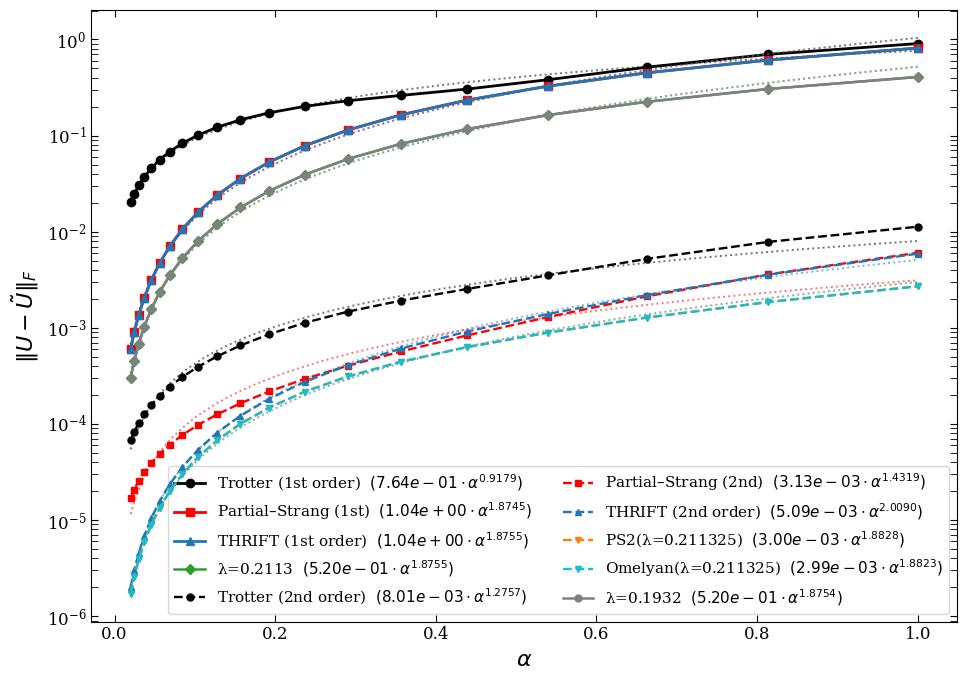

In [2]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 13,
    "axes.labelsize": 15,
    "legend.fontsize": 11,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "font.family": "serif",
})

# ============================================================
# LOAD
# ============================================================

def load_J_sweep(run_dir):
    with open(os.path.join(run_dir, 'data.json')) as f:
        data = json.load(f)
    print(f"[load] L={data['L']}  t={data['t']}  "
          f"J ∈ [{min(data['J_values']):.4f}, {max(data['J_values']):.4f}]  "
          f"({len(data['J_values'])} puntos)  métodos: {data['all_methods']}")
    return data

# ============================================================
# AJUSTE LEY DE POTENCIA  ← corregido
# ============================================================

def fit_power_law(J_values, errors):
    J   = np.array(J_values)
    err = np.array(errors)
    J   = J[:len(err)]                    # ← recorte por checkpoint parcial
    valid = (J > 0) & (err > 0) & np.isfinite(err)
    if valid.sum() < 2:
        return None
    n, log_a = np.polyfit(np.log(J[valid]), np.log(err[valid]), 1)
    a   = np.exp(log_a)
    n_r = round(n, 4)
    J_fit = np.linspace(J[valid].min(), J[valid].max(), 200)
    return a, n_r, J_fit, a * J_fit ** n

# ============================================================
# ESTILOS DINÁMICOS
# ============================================================

_BASE_STYLES = {
    'LTS':  dict(color='black',   ls='-',  marker='o', lw=2.0, ms=6, order=1),
    'PS':   dict(color='red',     ls='-',  marker='s', lw=2.0, ms=6, order=2),
    'THRIFT':   dict(color='#1f77b4', ls='-',  marker='^', lw=2.0, ms=6, order=3),
    'LTS2': dict(color='black',   ls='--', marker='o', lw=1.7, ms=5, order=5),
    'PS2':  dict(color='red',     ls='--', marker='s', lw=1.7, ms=5, order=6),
    'THRIFT2':  dict(color='#1f77b4', ls='--', marker='^', lw=1.7, ms=5, order=7),
}

_LABELS = {
    'LTS':  'LTS (1st order)',
    'PS':   'Partial–PS (1st)',
    'THRIFT':   'THRIFT (1st order)',
    'LTS2': 'LTS (2nd order)',
    'PS2':  'Partial–PS (2nd)',
    'THRIFT2':  'THRIFT (2nd order)',
}

_LAMBDA_COLORS  = ['#2ca02c', '#9467bd', '#e377c2', '#8c564b']
_PS2_OML_COLORS = ['#ff7f0e', '#17becf', '#d62728']


def _build_styles(methods):
    styles = dict(_BASE_STYLES)
    labels = dict(_LABELS)

    lam_1st = [m for m in methods
               if m not in styles
               and not any(m.startswith(p) for p in ('ULam2', 'OG'))
               and not m.endswith('2')]
    for i, m in enumerate(lam_1st):
        c = _LAMBDA_COLORS[i % len(_LAMBDA_COLORS)]
        styles[m] = dict(color=c, ls='-', marker='D', lw=1.8, ms=5, order=4)
        labels[m] = m

    ps2_oml = [m for m in methods
               if any(m.startswith(p) for p in ('ULam2', 'OG'))]
    for i, m in enumerate(ps2_oml):
        c = _PS2_OML_COLORS[i % len(_PS2_OML_COLORS)]
        styles[m] = dict(color=c, ls='--', marker='v', lw=1.7, ms=5, order=8)
        labels[m] = m

    return styles, labels

# ============================================================
# FIGURA — ERRORES  ← corregido
# ============================================================

def plot_errors_screen(data, save_fig=True, out_dir='figures'):

    J_values = np.array(data['J_values'])
    methods  = data['all_methods']
    errors   = data['errors_fixed']
    L        = data['L']
    t        = data['t']
    n_fixed  = data['n_fixed']
    dt_ref   = t / n_fixed

    # ── recortar J_values a los puntos ya calculados ──────────────────
    n_done   = len(errors[methods[0]])
    J_values = J_values[:n_done]

    styles, labels = _build_styles(methods)
    draw_order = sorted(methods, key=lambda m: styles.get(m, {}).get('order', 99))

    fig, ax = plt.subplots(figsize=(10, 7))

    for z, m in enumerate(draw_order, start=2):
        err_arr = np.array(errors[m])[:n_done]   # ← recorte consistente
        st  = styles.get(m, dict(color='gray', ls='-', marker='o', lw=1.8, ms=5))
        lbl = labels.get(m, m)

        fit = fit_power_law(J_values, err_arr)
        fit_label = ''
        if fit:
            a_fit, n_r, J_fit, err_fit = fit
            fit_label = rf'  $({a_fit:.2e} \cdot \alpha^{{{n_r:.4f}}})$'

        ax.plot(J_values, err_arr,
                linestyle=st['ls'], marker=st['marker'],
                color=st['color'], linewidth=st['lw'],
                markersize=st['ms'],
                label=lbl + fit_label, zorder=z)

        if fit:
            ax.plot(J_fit, err_fit, ':',
                    color=st['color'], linewidth=1.4, alpha=0.55, zorder=z)

    ax.set_yscale('log')
    ax.set_xlabel(r'$\alpha$', fontsize=16)
    ax.set_ylabel(r'$\|U - \tilde{U}\|_F$', fontsize=16)
   

    ax.tick_params(axis='both', which='both', direction='in',
                   top=True, right=True, length=5)

    ax.legend(frameon=True, framealpha=0.9, edgecolor='lightgray',
              fontsize=11, ncol=2, loc='best')

    plt.tight_layout()

    if save_fig:
        os.makedirs(out_dir, exist_ok=True)
        fname = os.path.join(out_dir, f'Errors_screen_L{L}_t{t}.pdf')
        plt.savefig(fname, bbox_inches='tight', dpi=150)
        print(f"[saved] {fname}")

    plt.show()
    return fig

# ============================================================
# EJECUTAR
# ============================================================

if __name__ == '__main__':
    data = load_J_sweep('results/Jsweep_XXMYY_L3_t1.0_n100')
    plot_errors_screen(data)

[load] L=3  t=1.0  n_fixed=100  J ∈ [0.0200, 1.0000]  (20 puntos)
       ratios: ['λ=0.1932 ÷ λ=0.2113', 'THRIFT ÷ Strang', 'THRIFT2 ÷ PS2(λ=0.211325)', 'Omelyan(λ=0.211325) ÷ PS2(λ=0.211325)']
[saved] ./Ratios_PRL_1col_L3_t1.0.pdf


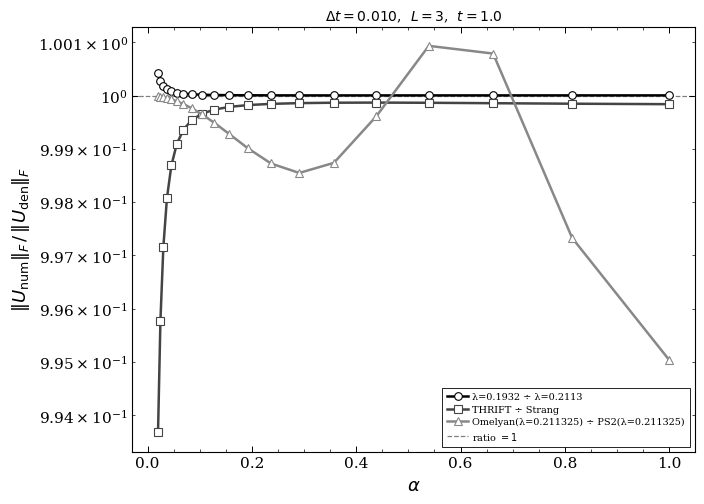

In [15]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

plt.rcParams.update({
    "font.size":           11,
    "axes.labelsize":      13,
    "legend.fontsize":      9,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "font.family":         "serif",
    "text.usetex":         False,
    "axes.linewidth":       0.8,
    "xtick.direction":     "in",
    "ytick.direction":     "in",
    "xtick.top":           True,
    "ytick.right":         True,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
})

def load_J_sweep(run_dir):
    with open(os.path.join(run_dir, 'data.json')) as f:
        data = json.load(f)
    print(f"[load] L={data['L']}  t={data['t']}  n_fixed={data['n_fixed']}  "
          f"J ∈ [{min(data['J_values']):.4f}, {max(data['J_values']):.4f}]  "
          f"({len(data['J_values'])} puntos)")
    print(f"       ratios: {list(data.get('ratios_fixed', {}).keys())}")
    return data

_RATIO_STYLES = [
    dict(color='#000000', ls='-', marker='o', lw=1.8, ms=5.5),
    dict(color='#444444', ls='-', marker='s', lw=1.8, ms=5.5),
    dict(color='#888888', ls='-', marker='^', lw=1.8, ms=5.5),
    dict(color='#bbbbbb', ls='-', marker='D', lw=1.8, ms=5.5),
]

def plot_ratios_prl(data, width,height, two_column=False, save_fig=True, out_dir='figures'):

    J_values     = np.array(data['J_values'])
    ratios_fixed = data.get('ratios_fixed', {})
    L            = data['L']
    t            = data['t']
    n_fixed      = data['n_fixed']
    dt_ref       = t / n_fixed

    if not ratios_fixed:
        print("[error] No hay ratios_fixed en el JSON.")
        return None

    # ── Excluir THRIFT2 / Partial-PS2 ────────────────────────────
    ratios_fixed = {k: v for k, v in ratios_fixed.items()
                    if 'THRIFT2' not in k}

    first_ratio = next(iter(ratios_fixed.values()))
    n_done      = len(first_ratio)
    J_values    = J_values[:n_done]

    # ← alto = ancho × ratio
    fig, ax = plt.subplots(figsize=(width, height))

    for i, (rname, rvals) in enumerate(ratios_fixed.items()):
        rv = np.array(rvals[:n_done])
        st = _RATIO_STYLES[i % len(_RATIO_STYLES)]
        ax.plot(J_values, rv,
                linestyle=st['ls'], marker=st['marker'],
                color=st['color'], linewidth=st['lw'],
                markersize=st['ms'],
                markerfacecolor='white',
                markeredgewidth=0.8, markeredgecolor=st['color'],
                label=rname, zorder=i + 2)

    ax.axhline(1.0, color='black', ls='--', lw=0.9, alpha=0.5,
               label='ratio $= 1$', zorder=1)

    ax.set_yscale('log')
    ax.set_xlabel(r'$\alpha$')
    ax.set_ylabel(r'$\Vert U_\mathrm{num} \Vert_F \,/\, \Vert U_\mathrm{den} \Vert_F$')
    ax.set_title(
        rf'$\Delta t={dt_ref:.3f}$,  $L={L}$,  $t={t}$',
        fontsize=10, pad=4
    )

    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.tick_params(which='major', length=4, width=0.7)
    ax.tick_params(which='minor', length=2, width=0.5)
    ax.grid(False)

    leg = ax.legend(frameon=True, framealpha=1.0,
                    edgecolor='black', fancybox=False,
                    fontsize=8 if two_column else 7,
                    ncol=1, loc='best',
                    handlelength=2.2, handletextpad=0.4,
                    labelspacing=0.35, borderpad=0.5)
    leg.get_frame().set_linewidth(0.6)

    plt.tight_layout(pad=0.5)

    if save_fig:
        os.makedirs(out_dir, exist_ok=True)
        tag   = '2col' if two_column else '1col'
        fname = os.path.join(out_dir, f'Ratios_PRL_{tag}_L{L}_t{t}.pdf')
        plt.savefig(fname, bbox_inches='tight', dpi=300)
        print(f"[saved] {fname}")

    plt.show()
    return fig

if __name__ == '__main__':
    data = load_J_sweep('results/Jsweep_XXMYY_L3_t1.0_n100')
    plot_ratios_prl(data,width=7, height=5,two_column=False)


[force_restart] Checkpoint borrado — empezando desde cero

Búsqueda de λ óptimo vs J  [paralelizado]
L=3  t=1.0  n_large=200  workers=32
λ ∈ [0.18, 0.24]  n_grid=10
J ∈ [0.0001, 1.0000]  (14 valores)
Resultados en: results/lambdasweep_XXMYY_L3_t1.0/data.json

[1/14]  J=0.0001
  U_exact: 0.1s
  grid [3269.7s]
  PS2           λ*=0.211329  err=1.1146e-11
  Omelyan       λ*=0.211326  err=1.0651e-11
  refinamiento [329.9s]
  tiempo acum: 3599.7s

[2/14]  J=0.0500
  U_exact: 0.1s
  grid [3230.5s]
  PS2           λ*=0.211216  err=2.6601e-06
  Omelyan       λ*=0.211219  err=2.6599e-06
  refinamiento [150.8s]
  tiempo acum: 6981.1s

[3/14]  J=0.1000
  U_exact: 0.1s
  grid [3214.3s]
  PS2           λ*=0.210981  err=1.0485e-05
  Omelyan       λ*=0.210995  err=1.0481e-05
  refinamiento [241.8s]
  tiempo acum: 10437.3s

[4/14]  J=0.1500
  U_exact: 3.0s
  grid [3225.7s]
  PS2           λ*=0.210876  err=2.3042e-05
  Omelyan       λ*=0.210911  err=2.3026e-05
  refinamiento [334.9s]
  tiempo acum: 1400

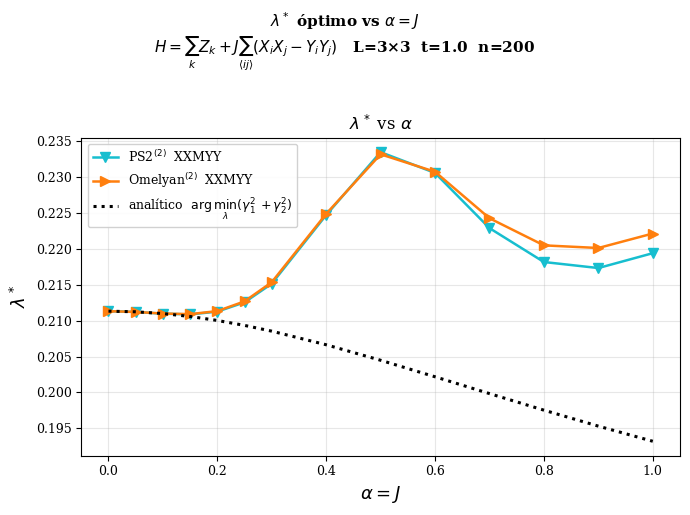

In [30]:
# ============================================================
# Búsqueda de λ óptimo vs J para U_λ̃2 y OG
# H = Σ_k Z_k + J Σ_{<ij>} (Xi Xj − Yi Yj)  [Jx=J, Jy=-J]
# ============================================================
# Versión paralelizada con concurrent.futures.ThreadPoolExecutor
# Siempre usa os.cpu_count() workers (máximo disponible).
#
# FLUJO:
#   # Paso 1: cómputo
#   run_dir = run_lambda_sweep(...)
#
#   # Paso 2: graficar λ* vs J  (XXMYY + Ising + analítico)
#   data = load_lambda_sweep(run_dir)
#   plot_lambda_vs_J(data, ising_run_dir='results/lambdasweep_Ising_L2_t1.0')
# ============================================================

import os, json, time
import numpy as np
from scipy.linalg import expm
from scipy.optimize import minimize_scalar
from concurrent.futures import ThreadPoolExecutor, as_completed
import matplotlib.pyplot as plt

_N_WORKERS = os.cpu_count()


# -----------------------------------------------------------------------
# CÁLCULO DE ERROR
# -----------------------------------------------------------------------

def _compute_error(n, method, lam, Jx, Jy, L, t_val, U_exact):
    system  = HeisenbergAniso2D(L, Jx, Jy, 0.0)
    cache   = GateCache()
    evolver = Evolver(system, t_val, cache)
    U       = evolver.compute_unitary(n, method, lam=lam)
    return float(np.linalg.norm(U - U_exact, 'fro'))


# -----------------------------------------------------------------------
# SERIALIZACIÓN
# -----------------------------------------------------------------------

def _serial(obj):
    if isinstance(obj, np.ndarray):                 return obj.tolist()
    if isinstance(obj, dict):                       return {k: _serial(v) for k, v in obj.items()}
    if isinstance(obj, list):                       return [_serial(x) for x in obj]
    if isinstance(obj, (np.floating, np.integer)):  return obj.item()
    return obj


# -----------------------------------------------------------------------
# OPTIMIZACIÓN ANALÍTICA  f(λ; α=J) = γ₁²(λ,α) + γ₂²(λ)
#   γ₁ = α·(1−6λ)/24      γ₂ = −1/12 + λ/2 − λ²/2
# -----------------------------------------------------------------------

def _f_analytical(lam, alpha):
    g1 = alpha * (1 - 6*lam) / 24
    g2 = -1/12 + lam/2 - lam**2/2
    return g1**2 + g2**2


def analytical_lambda_curve(J_values):
    lam_opts = []
    for J in J_values:
        res = minimize_scalar(
            lambda lam: _f_analytical(lam, J),
            bounds=(0.0, 1.0), method='bounded',
            options={'xatol': 1e-10},
        )
        lam_opts.append(res.x)
    return np.array(lam_opts)


# -----------------------------------------------------------------------
# CÓMPUTO
# -----------------------------------------------------------------------

def run_lambda_sweep(
    L             = 3,
    J_values      = None,
    t             = 1.0,
    n_large       = 200,
    lam_min       = 0.15,
    lam_max       = 0.25,
    n_grid        = 30,
    methods       = None,
    results_dir   = 'results',
    force_restart = False,
):
    if J_values is None:
        J_values = np.geomspace(0.02, 1.0, 10)
    J_values = np.array(J_values)

    if methods is None:
        methods = ['u_lambda2', 'og']

    method_labels = {'u_lambda2': 'ULam2', 'og': 'OG', 'u_lambda': 'U_λ̃'}

    run_dir   = os.path.join(results_dir, f"lambdasweep_XXMYY_L{L}_t{t}")
    os.makedirs(run_dir, exist_ok=True)
    ckpt_path = os.path.join(run_dir, 'data.json')

    if force_restart and os.path.exists(ckpt_path):
        os.remove(ckpt_path)
        print("[force_restart] Checkpoint borrado — empezando desde cero")

    results   = {m: [] for m in methods}
    start_idx = 0

    if os.path.exists(ckpt_path):
        with open(ckpt_path) as f:
            saved = json.load(f)
        if saved.get('methods') == methods:
            done = len(saved['results'][methods[0]])
            if done > 0:
                print(f"[checkpoint] Retomando desde J[{done}] "
                      f"({done}/{len(J_values)} ya completados)")
                results   = saved['results']
                start_idx = done
        else:
            print("[checkpoint] Métodos cambiaron — empezando desde cero")

    print(f"\n{'='*65}")
    print(f"Búsqueda de λ óptimo vs J  [paralelizado]")
    print(f"L={L}  t={t}  n_large={n_large}  workers={_N_WORKERS}")
    print(f"λ ∈ [{lam_min}, {lam_max}]  n_grid={n_grid}")
    print(f"J ∈ [{J_values[0]:.4f}, {J_values[-1]:.4f}]  ({len(J_values)} valores)")
    print(f"Resultados en: {ckpt_path}")
    print(f"{'='*65}\n")

    t_total = time.time()

    for j_idx in range(start_idx, len(J_values)):
        J  = J_values[j_idx]
        Jx, Jy =  J, -J

        print(f"[{j_idx+1}/{len(J_values)}]  J={J:.4f}")

        t0      = time.time()
        system  = HeisenbergAniso2D(L, Jx, Jy, 0.0)
        H_total = system.build_hamiltonian()
        U_exact = expm(-1j * H_total * t)
        print(f"  U_exact: {time.time()-t0:.1f}s", flush=True)

        t0        = time.time()
        grid_lams = np.linspace(lam_min, lam_max, n_grid)

        with ThreadPoolExecutor(max_workers=_N_WORKERS) as pool:
            futs = {
                pool.submit(_compute_error, n_large, mkey, lam,
                            Jx, Jy, L, t, U_exact): (mkey, i)
                for mkey in methods
                for i, lam in enumerate(grid_lams)
            }
            grid_errs_all = {mkey: np.empty(n_grid) for mkey in methods}
            for fut in as_completed(futs):
                mkey, i = futs[fut]
                grid_errs_all[mkey][i] = fut.result()

        print(f"  grid [{time.time()-t0:.1f}s]", flush=True)

        t0 = time.time()
        for mkey in methods:
            grid_errs = grid_errs_all[mkey]
            i_min     = np.argmin(grid_errs)
            lam_lo    = grid_lams[max(0, i_min - 1)]
            lam_hi    = grid_lams[min(n_grid - 1, i_min + 1)]

            result = minimize_scalar(
                lambda lam, mk=mkey: _compute_error(
                    n_large, mk, lam, Jx, Jy, L, t, U_exact),
                bounds=(lam_lo, lam_hi), method='bounded',
                options={'xatol': 1e-6},
            )
            lam_opt, err_opt = result.x, result.fun
            print(f"  {method_labels.get(mkey,mkey):<12}  "
                  f"λ*={lam_opt:.6f}  err={err_opt:.4e}", flush=True)

            results[mkey].append(dict(
                J=J, lam_opt=lam_opt, err_opt=err_opt,
                grid_lams=grid_lams.tolist(), grid_errs=grid_errs.tolist(),
            ))

        print(f"  refinamiento [{time.time()-t0:.1f}s]")
        print(f"  tiempo acum: {time.time()-t_total:.1f}s\n", flush=True)

        ckpt = dict(
            hamiltonian='sum_k Zk + J·sum_ij(XiXj - YiYj)',
            L=L, t=t, n_large=n_large,
            lam_min=lam_min, lam_max=lam_max, n_grid=n_grid,
            J_values=J_values.tolist(), methods=methods,
            method_labels=method_labels, results=results,
        )
        with open(ckpt_path, 'w') as f:
            json.dump(_serial(ckpt), f, indent=2)

    print(f"Total: {time.time()-t_total:.1f}s  →  {ckpt_path}")
    return run_dir


# -----------------------------------------------------------------------
# LOAD
# -----------------------------------------------------------------------

def load_lambda_sweep(run_dir):
    with open(os.path.join(run_dir, 'data.json')) as f:
        data = json.load(f)
    n_done = len(data['results'][data['methods'][0]])
    print(f"[load] L={data['L']}  t={data['t']}  "
          f"({n_done}/{len(data['J_values'])} pts)  métodos: {data['methods']}")
    return data


# -----------------------------------------------------------------------
# PLOT — única figura: λ* vs J
#
# Muestra en un solo gráfico:
#   · λ*(J) numérico XXMYY  por método  (línea sólida, marcador relleno)
#   · λ*(J) numérico Ising  por método  (línea discontinua, marcador hueco)
#   · λ analítico(J)        (negro punteado)
#
# Colores y marcadores tomados de la figura del PDF:
#   ULam2     → cian  '#17becf'  triángulo-abajo hueco  'v'
#   OG → naranja '#ff7f0e'  triángulo-derecha hueco  '>'
# -----------------------------------------------------------------------

# Estilos exactos del PDF
_STYLE = {
    'u_lambda2':     dict(color='#17becf', marker='v', ms=7, lw=1.8),
    'og': dict(color='#ff7f0e', marker='>', ms=7, lw=1.8),
    'u_lambda':  dict(color='#2ca02c', marker='D', ms=6, lw=1.8),
}
_LABELS = {
    'u_lambda2':     r'ULam2$^{(2)}$',
    'og': r'OG$^{(2)}$',
    'u_lambda':  r'$U_{\tilde\lambda}^{(1)}$',
}


def plot_lambda_vs_J(data, ising_run_dir=None,
                     save_fig=True, show=True, out_dir='figures'):
    """
    Una sola figura con λ* vs J:
      · XXMYY numérico   — sólido, marcador relleno
      · Ising numérico   — discontinuo, marcador hueco  (si ising_run_dir dado)
      · analítico        — negro punteado
    """
    J_values = np.array(data['J_values'])
    methods  = data['methods']
    results  = data['results']
    L, t     = data['L'], data['t']
    n_large  = data['n_large']

    n_done = len(results[methods[0]])
    J_done = J_values[:n_done]

    # Curva analítica
    lam_anal = analytical_lambda_curve(J_done)

    # Datos Ising
    ising_data = None
    if ising_run_dir is not None:
        ising_path = os.path.join(ising_run_dir, 'data.json')
        if os.path.exists(ising_path):
            with open(ising_path) as f:
                ising_data = json.load(f)
            n_ising = len(ising_data['results'][ising_data['methods'][0]])
            print(f"[load Ising] {n_ising} puntos")
        else:
            print(f"[warning] {ising_path} no encontrado — se omite Ising")

    fig, ax = plt.subplots(figsize=(7, 5))
    fig.suptitle(
        r'$\lambda^*$ óptimo vs $\alpha = J$'
        '\n'
        r'$H = \sum_k Z_k + J\sum_{\langle ij\rangle}(X_iX_j - Y_iY_j)$'
        f'   L={L}×{L}  t={t}  n={n_large}',
        fontsize=11, fontweight='bold', y=1.02,
    )

    for mkey in methods:
        st    = _STYLE.get(mkey, dict(color='gray', marker='o', ms=6, lw=1.8))
        label = _LABELS.get(mkey, mkey)

        # XXMYY — sólido, relleno
        lam_xxmyy = [r['lam_opt'] for r in results[mkey]]
        ax.plot(J_done, lam_xxmyy,
                color=st['color'], marker=st['marker'],
                ms=st['ms'], lw=st['lw'], ls='-',
                markerfacecolor=st['color'],
                label=f'{label}  XXMYY')

        # Ising — discontinuo, hueco
        if ising_data is not None and mkey in ising_data['results']:
            n_i    = len(ising_data['results'][mkey])
            J_i    = np.array(ising_data['J_values'])[:n_i]
            lam_i  = [r['lam_opt'] for r in ising_data['results'][mkey]]
            ax.plot(J_i, lam_i,
                    color=st['color'], marker=st['marker'],
                    ms=st['ms'], lw=st['lw'], ls='--',
                    markerfacecolor='white',
                    markeredgecolor=st['color'],
                    markeredgewidth=1.5,
                    label=f'{label}  Ising')

    # Analítico — negro punteado
    ax.plot(J_done, lam_anal,
            color='black', ls=':', lw=2.2, zorder=10,
            label=r'analítico  $\arg\min_\lambda(\gamma_1^2+\gamma_2^2)$')

    ax.set_xlabel(r'$\alpha = J$', fontsize=13)
    ax.set_ylabel(r'$\lambda^*$',  fontsize=13)
    ax.set_title(r'$\lambda^*$ vs $\alpha$', fontsize=12)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9, framealpha=0.9)

    plt.tight_layout()

    if save_fig:
        os.makedirs(out_dir, exist_ok=True)
        fname = os.path.join(out_dir, f'lambda_vs_J_L{L}_t{t}.png')
        plt.savefig(fname, dpi=150, bbox_inches='tight')
        print(f"[plot] {fname}")

    if show:
        plt.show()

    return fig


# -----------------------------------------------------------------------
# EJECUTAR
# -----------------------------------------------------------------------

if __name__ == '__main__':

    # Paso 1: cómputo
    run_dir = run_lambda_sweep(
        L             = 3,
        J_values      = np.array([0.0001,0.05,0.1,0.15,0.2,0.25]+[0.3,0.4,0.5,0.6,0.7,0.8,0.9,1]),
        t             = 1.0,
        n_large       = 200,
        lam_min       = 0.18,
        lam_max       = 0.24,
        n_grid        = 10,
        methods       = ['u_lambda2', 'og'],
        force_restart = True,   
    )

    # Paso 2: graficar
    data = load_lambda_sweep(run_dir)
    plot_lambda_vs_J(
        data,
        ising_run_dir = 'results/lambdasweep_Ising_L2_t1.0',  # ← ajustar
    )

[warning] results/lambdasweep_Ising_L2_t1.0/data.json no encontrado — se omite Ising
[plot] ./lambda_vs_J_L3_t1.0.pdf


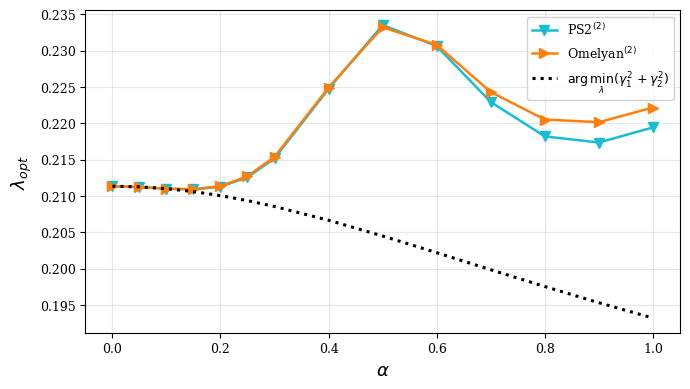

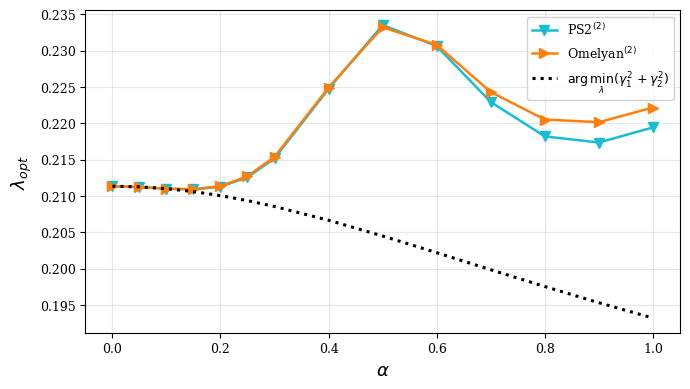

In [31]:
# -----------------------------------------------------------------------
# PLOT — única figura: λ* vs J
#
# Muestra en un solo gráfico:
#   · λ*(J) numérico XXMYY  por método  (línea sólida, marcador relleno)
#   · λ*(J) numérico Ising  por método  (línea discontinua, marcador hueco)
#   · λ analítico(J)        (negro punteado)
#
# Colores y marcadores tomados de la figura del PDF:
#   ULam2     → cian  '#17becf'  triángulo-abajo hueco  'v'
#   OG → naranja '#ff7f0e'  triángulo-derecha hueco  '>'
# -----------------------------------------------------------------------

# Estilos exactos del PDF
_STYLE = {
    'u_lambda2':     dict(color='#17becf', marker='v', ms=7, lw=1.8),
    'og': dict(color='#ff7f0e', marker='>', ms=7, lw=1.8),
    'u_lambda':  dict(color='#2ca02c', marker='D', ms=6, lw=1.8),
}
_LABELS = {
    'u_lambda2':     r'ULam2$^{(2)}$',
    'og': r'OG$^{(2)}$',
    'u_lambda':  r'$U_{\tilde\lambda}^{(1)}$',
}


def plot_lambda_vs_J(data, ising_run_dir=None,
                     save_fig=True, show=True, out_dir='figures'):
    """
    Una sola figura con λ* vs J:
      · XXMYY numérico   — sólido, marcador relleno
      · Ising numérico   — discontinuo, marcador hueco  (si ising_run_dir dado)
      · analítico        — negro punteado
    """
    J_values = np.array(data['J_values'])
    methods  = data['methods']
    results  = data['results']
    L, t     = data['L'], data['t']
    n_large  = data['n_large']

    n_done = len(results[methods[0]])
    J_done = J_values[:n_done]

    # Curva analítica
    lam_anal = analytical_lambda_curve(J_done)

    # Datos Ising
    ising_data = None
    if ising_run_dir is not None:
        ising_path = os.path.join(ising_run_dir, 'data.json')
        if os.path.exists(ising_path):
            with open(ising_path) as f:
                ising_data = json.load(f)
            n_ising = len(ising_data['results'][ising_data['methods'][0]])
            print(f"[load Ising] {n_ising} puntos")
        else:
            print(f"[warning] {ising_path} no encontrado — se omite Ising")

    fig, ax = plt.subplots(figsize=(7, 4))

    for mkey in methods:
        st    = _STYLE.get(mkey, dict(color='gray', marker='o', ms=6, lw=1.8))
        label = _LABELS.get(mkey, mkey)

        # XXMYY — sólido, relleno
        lam_xxmyy = [r['lam_opt'] for r in results[mkey]]
        ax.plot(J_done, lam_xxmyy,
                color=st['color'], marker=st['marker'],
                ms=st['ms'], lw=st['lw'], ls='-',
                markerfacecolor=st['color'],
                label=f'{label}')

        # Ising — discontinuo, hueco
        if ising_data is not None and mkey in ising_data['results']:
            n_i    = len(ising_data['results'][mkey])
            J_i    = np.array(ising_data['J_values'])[:n_i]
            lam_i  = [r['lam_opt'] for r in ising_data['results'][mkey]]
            ax.plot(J_i, lam_i,
                    color=st['color'], marker=st['marker'],
                    ms=st['ms'], lw=st['lw'], ls='--',
                    markerfacecolor='white',
                    markeredgecolor=st['color'],
                    markeredgewidth=1.5,
                    label=f'{label}  Ising')

    # Analítico — negro punteado
    ax.plot(J_done, lam_anal,
            color='black', ls=':', lw=2.2, zorder=10,
            label=r'$\arg\min_\lambda(\gamma_1^2+\gamma_2^2)$')

    ax.set_xlabel(r'$\alpha$', fontsize=13)
    ax.set_ylabel(r'$\lambda_{opt}$',  fontsize=13)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9, framealpha=0.9)

    plt.tight_layout()

    if save_fig:
        os.makedirs(out_dir, exist_ok=True)
        fname = os.path.join(out_dir, f'lambda_vs_J_L{L}_t{t}.pdf')
        plt.savefig(fname, bbox_inches='tight', dpi=300)
        print(f"[plot] {fname}")

    if show:
        plt.show()

    return fig


# -----------------------------------------------------------------------
# EJECUTAR
# -----------------------------------------------------------------------

# Paso 2: graficar
plot_lambda_vs_J(
    data,
    ising_run_dir = 'results/lambdasweep_Ising_L2_t1.0',  # ← ajustar
)

[checkpoint] Retomando desde J[14] (14/14 ya completados)

Búsqueda de λ óptimo vs J  [paralelizado]
L=2  t=1.0  n_large=200  workers=32
λ ∈ [0.18, 0.24]  n_grid=10
J ∈ [0.0001, 1.0000]  (14 valores)
Resultados en: results/lambdasweep_XXMYY_L2_t1.0_real/data.json

Total: 0.0s  →  results/lambdasweep_XXMYY_L2_t1.0_real/data.json
[load] L=2  t=1.0  (14/14 pts)  métodos: ['ps2', 'omelyan']
[load] L=2  t=1.0  (14/14 pts)  métodos: ['ps2', 'omelyan']
[warning] results/lambdasweep_Ising_L2_t1.0/data.json no encontrado — se omite Ising
[plot] results/plots/lambda_vs_J_L2_L2_t1.0.pdf


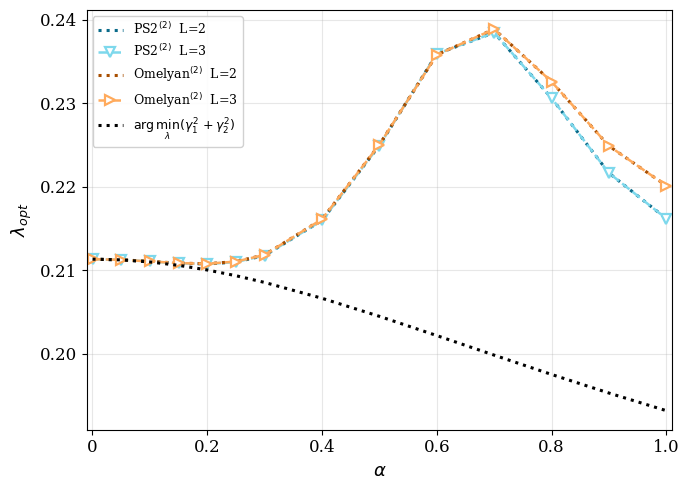

In [46]:
# ============================================================
# Búsqueda de λ óptimo vs J para U_λ̃2 y OG
# H = Σ_k Z_k + J Σ_{<ij>} (Xi Xj − Yi Yj)  [Jx=J, Jy=-J]
# ============================================================
# SEGURIDAD:
#   · EXISTING_L3_DIR  →  solo lectura (datos L=3, dir mal nombrado)
#   · El nuevo cómputo L=2 escribe SOLO en NEW_L2_RUN_DIR
# ============================================================

import os, json, time
import numpy as np
from scipy.linalg import expm
from scipy.optimize import minimize_scalar
from concurrent.futures import ThreadPoolExecutor, as_completed
import matplotlib.pyplot as plt

_N_WORKERS = os.cpu_count()

# -----------------------------------------------------------------------
# DIRECTORIOS  ← ajusta según tu estructura
# -----------------------------------------------------------------------
EXISTING_L3_DIR = 'results/lambdasweep_XXMYY_L2_t1.0'       # ← NO SE TOCA (L=3, mal nombrado)
ISING_DIR       = 'results/lambdasweep_Ising_L2_t1.0'       # ← opcional
NEW_L2_RUN_DIR  = 'results/lambdasweep_XXMYY_L2_t1.0_real'  # nuevo cómputo L=2


# -----------------------------------------------------------------------
# CÁLCULO DE ERROR
# -----------------------------------------------------------------------

def _compute_error(n, method, lam, Jx, Jy, L, t_val, U_exact):
    system  = HeisenbergAniso2D(L, Jx, Jy, 0.0)
    cache   = GateCache()
    evolver = Evolver(system, t_val, cache)
    U       = evolver.compute_unitary(n, method, lam=lam)
    return float(np.linalg.norm(U - U_exact, 'fro'))


# -----------------------------------------------------------------------
# SERIALIZACIÓN
# -----------------------------------------------------------------------

def _serial(obj):
    if isinstance(obj, np.ndarray):                 return obj.tolist()
    if isinstance(obj, dict):                       return {k: _serial(v) for k, v in obj.items()}
    if isinstance(obj, list):                       return [_serial(x) for x in obj]
    if isinstance(obj, (np.floating, np.integer)):  return obj.item()
    return obj


# -----------------------------------------------------------------------
# OPTIMIZACIÓN ANALÍTICA
# -----------------------------------------------------------------------

def _f_analytical(lam, alpha):
    g1 = alpha * (1 - 6*lam) / 24
    g2 = -1/12 + lam/2 - lam**2/2
    return g1**2 + g2**2


def analytical_lambda_curve(J_values):
    lam_opts = []
    for J in J_values:
        res = minimize_scalar(
            lambda lam: _f_analytical(lam, J),
            bounds=(0.0, 1.0), method='bounded',
            options={'xatol': 1e-10},
        )
        lam_opts.append(res.x)
    return np.array(lam_opts)


# -----------------------------------------------------------------------
# CÓMPUTO (escribe SOLO en run_dir)
# -----------------------------------------------------------------------

def run_lambda_sweep(
    L             = 2,
    J_values      = None,
    t             = 1.0,
    n_large       = 200,
    lam_min       = 0.18,
    lam_max       = 0.24,
    n_grid        = 10,
    methods       = None,
    run_dir       = None,
    results_dir   = 'results',
    force_restart = False,
):
    if J_values is None:
        J_values = np.geomspace(0.02, 1.0, 10)
    J_values = np.array(J_values)

    if methods is None:
        methods = ['u_lambda2', 'og']

    method_labels = {'u_lambda2': 'ULam2', 'og': 'OG', 'u_lambda': 'U_λ̃'}

    if run_dir is None:
        run_dir = os.path.join(results_dir, f"lambdasweep_XXMYY_L{L}_t{t}_new")
    os.makedirs(run_dir, exist_ok=True)
    ckpt_path = os.path.join(run_dir, 'data.json')

    if force_restart and os.path.exists(ckpt_path):
        os.remove(ckpt_path)
        print("[force_restart] Checkpoint borrado — empezando desde cero")

    results   = {m: [] for m in methods}
    start_idx = 0

    if os.path.exists(ckpt_path):
        with open(ckpt_path) as f:
            saved = json.load(f)
        if saved.get('methods') == methods:
            done = len(saved['results'][methods[0]])
            if done > 0:
                print(f"[checkpoint] Retomando desde J[{done}] "
                      f"({done}/{len(J_values)} ya completados)")
                results   = saved['results']
                start_idx = done
        else:
            print("[checkpoint] Métodos cambiaron — empezando desde cero")

    print(f"\n{'='*65}")
    print(f"Búsqueda de λ óptimo vs J  [paralelizado]")
    print(f"L={L}  t={t}  n_large={n_large}  workers={_N_WORKERS}")
    print(f"λ ∈ [{lam_min}, {lam_max}]  n_grid={n_grid}")
    print(f"J ∈ [{J_values[0]:.4f}, {J_values[-1]:.4f}]  ({len(J_values)} valores)")
    print(f"Resultados en: {ckpt_path}")
    print(f"{'='*65}\n")

    t_total = time.time()

    for j_idx in range(start_idx, len(J_values)):
        J      = J_values[j_idx]
        Jx, Jy = J, -J

        print(f"[{j_idx+1}/{len(J_values)}]  J={J:.4f}")

        t0      = time.time()
        system  = HeisenbergAniso2D(L, Jx, Jy, 0.0)
        H_total = system.build_hamiltonian()
        U_exact = expm(-1j * H_total * t)
        print(f"  U_exact: {time.time()-t0:.1f}s", flush=True)

        t0        = time.time()
        grid_lams = np.linspace(lam_min, lam_max, n_grid)

        with ThreadPoolExecutor(max_workers=_N_WORKERS) as pool:
            futs = {
                pool.submit(_compute_error, n_large, mkey, lam,
                            Jx, Jy, L, t, U_exact): (mkey, i)
                for mkey in methods
                for i, lam in enumerate(grid_lams)
            }
            grid_errs_all = {mkey: np.empty(n_grid) for mkey in methods}
            for fut in as_completed(futs):
                mkey, i = futs[fut]
                grid_errs_all[mkey][i] = fut.result()

        print(f"  grid [{time.time()-t0:.1f}s]", flush=True)

        t0 = time.time()
        for mkey in methods:
            grid_errs = grid_errs_all[mkey]
            i_min     = np.argmin(grid_errs)
            lam_lo    = grid_lams[max(0, i_min - 1)]
            lam_hi    = grid_lams[min(n_grid - 1, i_min + 1)]

            result = minimize_scalar(
                lambda lam, mk=mkey: _compute_error(
                    n_large, mk, lam, Jx, Jy, L, t, U_exact),
                bounds=(lam_lo, lam_hi), method='bounded',
                options={'xatol': 1e-6},
            )
            lam_opt, err_opt = result.x, result.fun
            print(f"  {method_labels.get(mkey,mkey):<12}  "
                  f"λ*={lam_opt:.6f}  err={err_opt:.4e}", flush=True)

            results[mkey].append(dict(
                J=J, lam_opt=lam_opt, err_opt=err_opt,
                grid_lams=grid_lams.tolist(), grid_errs=grid_errs.tolist(),
            ))

        print(f"  refinamiento [{time.time()-t0:.1f}s]")
        print(f"  tiempo acum: {time.time()-t_total:.1f}s\n", flush=True)

        ckpt = dict(
            hamiltonian='sum_k Zk + J·sum_ij(XiXj - YiYj)',
            L=L, t=t, n_large=n_large,
            lam_min=lam_min, lam_max=lam_max, n_grid=n_grid,
            J_values=J_values.tolist(), methods=methods,
            method_labels=method_labels, results=results,
        )
        with open(ckpt_path, 'w') as f:
            json.dump(_serial(ckpt), f, indent=2)

    print(f"Total: {time.time()-t_total:.1f}s  →  {ckpt_path}")
    return run_dir


# -----------------------------------------------------------------------
# LOAD
# -----------------------------------------------------------------------

def load_lambda_sweep(run_dir):
    path = os.path.join(run_dir, 'data.json')
    with open(path) as f:
        data = json.load(f)
    n_done = len(data['results'][data['methods'][0]])
    print(f"[load] L={data['L']}  t={data['t']}  "
          f"({n_done}/{len(data['J_values'])} pts)  métodos: {data['methods']}")
    return data


# -----------------------------------------------------------------------
# ESTILOS
# -----------------------------------------------------------------------

_STYLE = {
    'u_lambda2':     dict(marker='v', ms=7, lw=1.8),
    'og': dict(marker='>', ms=7, lw=1.8),
    'u_lambda':  dict(marker='D', ms=6, lw=1.8),
}
_LABELS = {
    'u_lambda2':     r'ULam2$^{(2)}$',
    'og': r'OG$^{(2)}$',
    'u_lambda':  r'$U_{\tilde\lambda}^{(1)}$',
}

# Mismo tono por método: oscuro para L=2 (visible, saturado),
# claro para L=3 e Ising (pálido pero legible).
#   ULam2     base cian    → oscuro '#0a6b8a'   claro '#7dd8ec'
#   OG base naranja → oscuro '#a84e00'   claro '#ffaa5c'
_COLOR_DARK  = {'u_lambda2': '#0a6b8a', 'og': '#a84e00', 'u_lambda': '#1a6e1a'}
_COLOR_LIGHT = {'u_lambda2': '#7dd8ec', 'og': '#ffaa5c', 'u_lambda': '#7ed67e'}


# -----------------------------------------------------------------------
# PLOT — λ* vs J
#
#   L=2   → color OSCURO  · línea sólida  (-)  · marcador relleno
#   L=3   → color CLARO   · línea discon. (--) · marcador hueco
#   Ising → color CLARO   · línea puntead (:)  · marcador hueco
#   analítico → negro punteado (:)
# -----------------------------------------------------------------------

def plot_lambda_vs_J_overlay(
    data_a,
    data_b        = None,
    label_a       = None,
    label_b       = None,
    ising_run_dir = None,
    save_fig      = True,
    show          = True,
    out_dir       = 'figures',
):
    def _get_done(data):
        n = len(data['results'][data['methods'][0]])
        return np.array(data['J_values'])[:n]

    J_a = _get_done(data_a)
    La  = data_a['L']
    ta  = data_a['t']

    label_a = label_a or f'L={La}'
    label_b = label_b or (f'L={data_b["L"]}' if data_b else None)

    lam_anal = analytical_lambda_curve(J_a)

    ising_data = None
    if ising_run_dir is not None:
        ising_path = os.path.join(ising_run_dir, 'data.json')
        if os.path.exists(ising_path):
            with open(ising_path) as f:
                ising_data = json.load(f)
            n_ising = len(ising_data['results'][ising_data['methods'][0]])
            print(f"[load Ising] {n_ising} puntos")
        else:
            print(f"[warning] {ising_path} no encontrado — se omite Ising")

    fig, ax = plt.subplots(figsize=(7, 5))

    methods = data_a['methods']

    for mkey in methods:
        st   = _STYLE.get(mkey, dict(marker='o', ms=6, lw=1.8))
        lbl  = _LABELS.get(mkey, mkey)
        c_dk = _COLOR_DARK.get(mkey,  '#333333')
        c_lt = _COLOR_LIGHT.get(mkey, '#aaaaaa')

        # L=2 — oscuro · punteado · sin marcador
        lam_a = [r['lam_opt'] for r in data_a['results'][mkey]]
        ax.plot(J_a, lam_a,
                color=c_dk, lw=st['lw']+0.4, ls=':',
                label=f'{lbl}  {label_a}')

        # L=3 — claro · discontinuo · hueco
        if data_b is not None and mkey in data_b['results']:
            J_b   = _get_done(data_b)
            lam_b = [r['lam_opt'] for r in data_b['results'][mkey]]
            ax.plot(J_b, lam_b,
                    color=c_lt, marker=st['marker'],
                    ms=st['ms'], lw=st['lw'], ls='--',
                    markerfacecolor='white',
                    markeredgecolor=c_lt, markeredgewidth=1.6,
                    label=f'{lbl}  {label_b}')

        # Ising — claro · punteado · hueco
        if ising_data is not None and mkey in ising_data['results']:
            n_i   = len(ising_data['results'][mkey])
            J_i   = np.array(ising_data['J_values'])[:n_i]
            lam_i = [r['lam_opt'] for r in ising_data['results'][mkey]]
            ax.plot(J_i, lam_i,
                    color=c_lt, marker=st['marker'],
                    ms=st['ms'], lw=st['lw'], ls=':',
                    markerfacecolor='white',
                    markeredgecolor=c_lt, markeredgewidth=1.5,
                    label=f'{lbl}  Ising')

    # Analítico — negro punteado
    ax.plot(J_a, lam_anal,
            color='black', ls=':', lw=2.2, zorder=10,
            label=r'$\arg\min_\lambda(\gamma_1^2+\gamma_2^2)$')

    # Eje x: empieza en 0, termina justo pasado 1.0
    ax.set_xlim(left=-0.01, right=1.01)

    # Ticks explícitos incluyendo 0
    x_ticks = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
    ax.set_xticks(x_ticks)
    ax.set_xticklabels([str(x) for x in x_ticks], fontsize=12)
    ax.tick_params(axis='y', labelsize=12)

    ax.set_xlabel(r'$\alpha$',        fontsize=13)
    ax.set_ylabel(r'$\lambda_{opt}$', fontsize=13)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9, framealpha=0.9)

    plt.tight_layout()

    if save_fig:
        os.makedirs(out_dir, exist_ok=True)
        Lb_str = f'_L{data_b["L"]}' if data_b else ''
        fname  = os.path.join(out_dir, f'lambda_vs_J_L{La}{Lb_str}_t{ta}.pdf')
        plt.savefig(fname, bbox_inches='tight', dpi=300)
        print(f"[plot] {fname}")

    if show:
        plt.show()

    return fig


# -----------------------------------------------------------------------
# EJECUTAR
# -----------------------------------------------------------------------

if __name__ == '__main__':

    J_VALUES = np.array([0.0001, 0.05, 0.1, 0.15, 0.2, 0.25,
                         0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])

    # Paso 1: cómputo L=2  (nunca toca EXISTING_L3_DIR)
    run_dir_new = run_lambda_sweep(
        L             = 2,
        J_values      = J_VALUES,
        t             = 1.0,
        n_large       = 200,
        lam_min       = 0.18,
        lam_max       = 0.24,
        n_grid        = 10,
        methods       = ['u_lambda2', 'og'],
        run_dir       = NEW_L2_RUN_DIR,
        force_restart = False,
    )

    # Paso 2: cargar y graficar
    data_L3 = load_lambda_sweep(EXISTING_L3_DIR)   # solo lectura
    data_L2 = load_lambda_sweep(run_dir_new)

    plot_lambda_vs_J_overlay(
        data_a        = data_L2,
        data_b        = data_L3,
        label_a       = 'L=2',
        label_b       = 'L=3',
        ising_run_dir = ISING_DIR,
        out_dir       = 'results/plots',
    )